<a href="https://colab.research.google.com/github/Melonangie/Galaxy-Vision/blob/main/EDA_Starlight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA espectral para clasificación morfológica de galaxias (MaNGA + STARLIGHT)

## ¿Qué es la morfología de una galaxia?
La **secuencia de Hubble** (Hubble 1926, 1936) ordena las galaxias en elípticas (E), lenticulares (S0)
y espirales (Sa→Sd), más las irregulares (Im). De Vaucouleurs (1959) la extendió con el índice numérico
**T-type** (RC3; de Vaucouleurs et al. 1991):

| T | -5 | -2 | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11* |
|---|----|----|---|---|---|---|---|---|---|---|---|---|----|----|
| Tipo | E | S0 | S0a | Sa | Sab | Sb | Sbc | Sc | Scd | Sd | Sdm | Sm | Im | S (sin subtipo, en este catálogo) |

**¿Por qué el espectro sirve para separar tipos morfológicos?** Porque la morfología está ligada a la
historia de formación estelar (Roberts & Haynes 1994; Kennicutt 1998; Blanton & Moustakas 2009; Conselice 2014):

* **Tipos tempranos (E, S0):** dominan estrellas viejas (>5 Gyr) y ricas en metales. Su continuo es rojo y tiene un
  **salto en 4000 Å (D4000)** grande. Las líneas de absorción (Ca II H&K, banda G, Mg b, NaD) son intensas.
  Casi no hay emisión; cuando la hay, suele ser débil y de tipo **LINER/"retirada"**
  (Heckman 1980; Stasińska et al. 2008; Cid Fernandes et al. 2011).
* **Espirales tardías e irregulares (Sc–Im):** tienen formación estelar en curso. El continuo es azul y aparecen
  absorciones de Balmer de estrellas A (Hδ_A alto). Las líneas de emisión nebular son intensas
  (Hα, Hβ, [O II], [O III]) y en el diagrama BPT caen en la rama de **formación estelar**
  (Kennicutt 1992; Strateva et al. 2001; Kauffmann et al. 2003).
* **Espirales intermedias (Sa–Sbc):** son una mezcla de bulbo viejo y disco joven. Muchas caen en la zona
  "compuesta" del BPT.

## Datos
* `*.fits.gz`: espectro 1D integrado de cada galaxia MaNGA (Bundy et al. 2015). Se usan solo `WAVE` y `FLUX_FoV`.
  λ está en **vacío** y en el marco **observado**.
* `*.out`: síntesis de poblaciones estelares con STARLIGHT (Cid Fernandes et al. 2005) y la base BC03
  (Bruzual & Charlot 2003). Contiene el vector de poblaciones (edades y metalicidades), la extinción estelar A_V,
  la cinemática (v0, σ) y el espectro sintético **ya en reposo**.
* Catálogo morfológico (`.fits`): Type, Ttype, z (NSA), LogMass, inclinación y PETRO_TH90. Probablemente viene
  del catálogo visual de MaNGA (Vázquez-Mata et al. 2022) o del VAC de Domínguez Sánchez et al. (2022).
  **No se le hace EDA**, solo se usa como complemento.

In [1]:
# Instalamos astroML (astropy, numpy, scipy, sklearn y seaborn ya vienen en Colab)
!pip install -q astroML

In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# --- Librerías astronómicas ---
from astropy.table import Table                 # lectura de tablas FITS (también .fits.gz)
from astropy import units as u
from astropy.constants import c
from astropy.modeling import models, fitting    # ajuste de gaussianas a las líneas de emisión
from astropy.visualization import hist as hist_astro  # histogramas con bins de Knuth (heredado de astroML)
from astroML.stats import sigmaG                # dispersión robusta: 0.7413*(q75-q25) (Ivezić et al. 2014)

# --- Estadística y aprendizaje automático ---
from scipy.integrate import trapezoid
from scipy.stats import kruskal, spearmanr
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
C_KMS = c.to(u.km / u.s).value   # velocidad de la luz en km/s (para corregir por v0 de STARLIGHT)

In [3]:
from google.colab import drive
drive.mount('/content/drive')

!cp "/content/drive/MyDrive/Proyecto_morfologia/data/morfologia.fits" /content/
!cp "/content/drive/MyDrive/Proyecto_morfologia/data/MPL-11.zip" /content/
!cp "/content/drive/MyDrive/Proyecto_morfologia/data/FoV-OUT.zip" /content/

!unzip -o -q /content/MPL-11.zip -d /content/fits
!unzip -o -q /content/FoV-OUT.zip -d /content/out

!df -h /content

!ls /content
!ls /content/fits/MPL-11 | wc -l
!ls /content/out/FoV-OUT | wc -l

#%cd /content/fits/MPL-11
#!rename 's/-1D.fits.gz//' *.fits.gz
#!ls -U | head -4

#%cd /content/out/FoV-OUT
#!rename 's/-1D.out//' *.out
#!ls -U | head -4

Mounted at /content/drive
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G  5.9G  102G   6% /
drive  fits  FoV-OUT.zip  morfologia.fits  MPL-11.zip  out  sample_data
10243
10243


In [4]:
RUTA_FITS   = "/content/fits/MPL-11"  # one 1D .fits spectrum per galaxy
RUTA_OUT    = "/content/out/FoV-OUT"   # STARLIGHT outputs
RUTA_MORF = "/content/morfologia.fits"
RUTA_RES   = "/content/drive/MyDrive/Proyecto_morfologia/eda_results" # tables & figures are saved here

fits_files = sorted(glob.glob(f"{RUTA_FITS}/*"))
# STARLIGHT outputs may be called *.out or *-out.txt -> accept both
out_files  = sorted(glob.glob(f"{RUTA_OUT}/*"))

print(len(fits_files), "FITS spectra, ", len(out_files), "STARLIGHT outputs")

10243 FITS spectra,  10243 STARLIGHT outputs


Catálogo morfológico

In [6]:
# Leemos el catálogo morfológico. Solo lo usamos para obtener Ttype, z y propiedades de apoyo.
morf = Table.read(RUTA_MORF).to_pandas()

# En FITS las columnas de texto suelen llegar como bytes: las convertimos a str
for col in morf.columns:
    if morf[col].dtype == object:
        morf[col] = morf[col].apply(lambda v: v.decode().strip() if isinstance(v, bytes) else str(v).strip())

morf['Ttype'] = morf['Ttype'].astype(int)
morf = morf.drop_duplicates('name').set_index('name')

# Nombres y colores de cada T-type (rojo = temprano, azul = tardío)
NOMBRE_TTYPE = {-5: 'E', -2: 'S0', 0: 'S0a', 1: 'Sa', 2: 'Sab', 3: 'Sb', 4: 'Sbc', 5: 'Sc',
                6: 'Scd', 7: 'Sd', 8: 'Sdm', 9: 'Sm', 10: 'Im', 11: 'S?'}
ORDEN_TTYPE = sorted(NOMBRE_TTYPE)
COLOR_TTYPE = dict(zip(ORDEN_TTYPE, plt.cm.turbo_r(np.linspace(0.02, 0.98, len(ORDEN_TTYPE)))))

# Grupos amplios: hay pocos objetos en algunos T-types, así que agrupamos para el clasificador
def grupo_amplio(t):
    if t == -5:          return 'E'
    if t in (-2, 0):     return 'S0-S0a'
    if t in (1, 2):      return 'Sa-Sab'
    if t in (3, 4):      return 'Sb-Sbc'
    if t in (5, 6, 7):   return 'Sc-Sd'
    if t in (8, 9, 10):  return 'Sdm-Im'
    return 'S?'
ORDEN_GRUPO = ['E', 'S0-S0a', 'Sa-Sab', 'Sb-Sbc', 'Sc-Sd', 'Sdm-Im', 'S?']

print(morf.head())
print(morf['Ttype'].value_counts().sort_index())

                        objra     objdec   Type  Ttype     nsa_z    LogMass  \
name                                                                          
manga-10001-12701  133.371091  57.598425    Sbc      4  0.039207   9.486857   
manga-10001-12702  133.685670  57.480250  SABbc      4  0.040811   9.727675   
manga-10001-12703  136.017160  57.092329  SABbc      4  0.046209  10.136514   
manga-10001-12704  133.989967  57.677968     Sd      7  0.014122   9.632117   
manga-10001-12705  136.751375  57.451437    Sbc      4  0.046235  10.113519   

                        incl  PETRO_TH90  
name                                      
manga-10001-12701  70.407211    7.880948  
manga-10001-12702  59.454862   14.147447  
manga-10001-12703  78.126652   13.001850  
manga-10001-12704  81.373073   28.682878  
manga-10001-12705  61.871475   11.039550  
Ttype
-5     1809
-2     1317
 0      615
 1     1085
 2     1051
 3     1126
 4     1034
 5     1026
 6      462
 7      352
 8       79
 9     

líneas espectrales

In [8]:
# Las longitudes de onda de MaNGA están en VACÍO, así que usamos longitudes de onda de laboratorio en vacío
# (las mismas del DAP de MaNGA; Westfall et al. 2019; Belfiore et al. 2019).
# Las líneas cercanas se ajustan juntas ("grupo") para no contaminarse entre sí.
LINEAS_EMISION = {
    'OII':     [('OII_3726', 3727.09), ('OII_3729', 3729.88)],   # doblete; se suma después
    'NeIII':   [('NeIII_3869', 3869.86)],
    'Hd':      [('Hd_4102', 4102.89)],
    'Hg_OIII': [('Hg_4341', 4341.69), ('OIII_4363', 4364.44)],   # [OIII]4363 está a 23 Å de Hγ
    'Hb':      [('Hb_4861', 4862.69)],
    'OIII':    [('OIII_4959', 4960.30), ('OIII_5007', 5008.24)],
    'HeI':     [('HeI_5876', 5877.25)],
    'OI':      [('OI_6300', 6302.05)],
    'Ha_NII':  [('NII_6548', 6549.86), ('Ha_6563', 6564.61), ('NII_6584', 6585.27)],
    'SII':     [('SII_6717', 6718.29), ('SII_6731', 6732.67)],
    'ArIII':   [('ArIII_7136', 7137.76)],
}

# Absorciones (vacío) solo para marcarlas en las gráficas
LINEAS_ABSORCION = {'K': 3934.78, 'H': 3969.59, 'G': 4305.6, 'Mg b': 5176.7,
                    'NaD': 5893.6, 'CaII': 8500.4, 'CaII ': 8544.4, 'CaII  ': 8664.5}

# Los índices de Lick y otros se definieron en AIRE. Los pasamos a vacío con la fórmula de
# Ciddor (1996), en la versión usada por VALD/SDSS.
def aire_a_vacio(l_aire):
    l = np.asarray(l_aire, dtype=float)
    s2 = (1e4 / l) ** 2
    n = 1 + 8.336624212083e-5 + 2.408926869968e-2 / (130.1065924522 - s2) + 1.599740894897e-4 / (38.92568793293 - s2)
    return l * n

# Formato: nombre: (banda central, pseudo-continuo azul, pseudo-continuo rojo), en Å y en aire
INDICES_AIRE = {
    'CaII_K': ((3923.7, 3943.7), (3903.0, 3923.0), (3943.7, 3953.0)),   # ventanas simples (aprox.)
    'CaII_H': ((3958.5, 3978.5), (3943.7, 3953.0), (3990.0, 4010.0)),   # ¡incluye Hε 3970!
    'HdA':    ((4083.500, 4122.250), (4041.600, 4079.750), (4128.500, 4161.000)),  # Worthey & Ottaviani 1997
    'G4300':  ((4281.375, 4316.375), (4266.375, 4282.625), (4318.875, 4335.125)),  # Lick (Worthey 1994)
    'HgA':    ((4319.750, 4363.500), (4283.500, 4319.750), (4367.250, 4419.750)),  # Worthey & Ottaviani 1997
    'Mgb':    ((5160.125, 5192.625), (5142.625, 5161.375), (5191.375, 5206.375)),  # Lick
    'NaD':    ((5876.875, 5909.375), (5860.625, 5875.625), (5922.125, 5948.125)),  # Lick
    'CaT1':   ((8483.0, 8513.0), (8447.5, 8462.5), (8842.5, 8857.5)),  # Díaz, Terlevich & Terlevich 1989
    'CaT2':   ((8527.0, 8557.0), (8447.5, 8462.5), (8842.5, 8857.5)),
    'CaT3':   ((8647.0, 8677.0), (8447.5, 8462.5), (8842.5, 8857.5)),
}
INDICES = {k: tuple(tuple(aire_a_vacio(b)) for b in v) for k, v in INDICES_AIRE.items()}
D4000_AZUL, D4000_ROJO = aire_a_vacio((3850, 3950)), aire_a_vacio((4000, 4100))  # D4000n (Balogh et al. 1999)

lectura de espectros .fits.gz y salidas STARLIGHT

In [11]:
def leer_espectro_fits(ruta, z):
    """Lee WAVE y FLUX_FoV y los pasa al marco en reposo."""
    tabla = Table.read(ruta)                                 # astropy descomprime .gz automáticamente
    cols = {nombre.upper(): nombre for nombre in tabla.colnames}  # no importa si es FLUX_FoV o FLUX_FOV
    wave_obs = np.array(tabla[cols['WAVE']], dtype=float).ravel()
    flux     = np.array(tabla[cols['FLUX_FOV']], dtype=float).ravel()

    flux[flux == 0] = np.nan              # los bordes sin datos vienen en 0 -> NaN
    wave_rest = wave_obs / (1 + z)        # λ_reposo = λ_obs / (1+z)
    flux_rest = flux * (1 + z)            # F_λ en reposo (conserva la energía; no afecta cocientes)
    return wave_rest, flux_rest

def leer_starlight(ruta):
    """Lee un .out de STARLIGHT: parámetros [etiqueta], vector de poblaciones y espectro sintético."""
    with open(ruta) as f:
        lineas = f.readlines()

    # 1) Parámetros escalares: líneas del tipo "valor   [etiqueta]"
    info = {}
    for l in lineas:
        if '[' in l and ']' in l and not l.startswith('#'):
            etiqueta = ' '.join(l[l.index('[') + 1: l.index(']')].split())
            try:
                info[etiqueta] = float(l.split()[0])
            except ValueError:
                pass

    # 2) Vector de poblaciones (una fila por SSP)
    i0 = next(i for i, l in enumerate(lineas) if 'x_j(%)' in l and 'Mini_j' in l)
    filas = []
    for l in lineas[i0 + 1:]:
        if l.strip() == '':
            break
        filas.append(l.split())
    columnas = ['j', 'x', 'Mini', 'Mcor', 'edad', 'Z', 'LM', 'YAV', 'Mstars', 'comp',
                'aFe', 'SSP_chi2r', 'SSP_adev', 'SSP_AV', 'SSP_x']
    pob = pd.DataFrame(filas, columns=columnas[:len(filas[0])])
    for col in pob.columns:
        if col != 'comp':
            pob[col] = pd.to_numeric(pob[col])

    # 3) Espectro sintético (l_obs ya en reposo; wei: >0 usado, 0 máscara, -1 recortado, -2 sin datos)
    i1 = next(i for i, l in enumerate(lineas) if '## Synthetic spectrum' in l)
    n = int(lineas[i1 + 1].split()[0])
    esp = pd.DataFrame(np.loadtxt(lineas[i1 + 2: i1 + 2 + n]), columns=['l_obs', 'f_obs', 'f_syn', 'wei'])
    return {'info': info, 'pob': pob, 'espectro': esp}


def propiedades_starlight(sl):
    """Resume la síntesis en propiedades físicas (Cid Fernandes et al. 2005)."""
    info, pob = sl['info'], sl['pob']
    x = pob['x'] / pob['x'].sum()          # fracción de LUZ de cada SSP
    m = pob['Mcor'] / pob['Mcor'].sum()    # fracción de MASA de cada SSP
    logt = np.log10(pob['edad'])
    return {
        'logEdad_L': (x * logt).sum(),
        'logEdad_M': (m * logt).sum(),
        'Z_L': (x * pob['Z']).sum(),
        'Z_M': (m * pob['Z']).sum(),
        'xY': x[pob['edad'] < 1e8].sum(),                              # joven: < 100 Myr
        'xI': x[(pob['edad'] >= 1e8) & (pob['edad'] <= 1e9)].sum(),    # intermedia
        'xO': x[pob['edad'] > 1e9].sum(),                              # vieja: > 1 Gyr
        'AV_estelar': info.get('AV_min (mag)', np.nan),
        'v0': info.get('v0_min (km/s)', np.nan),
        'sigma_estelar': info.get('vd_min (km/s)', np.nan),            # dispersión de velocidades
        'chi2': info.get('chi2/Nl_eff', np.nan),
        'adev': info.get('adev (%)', np.nan),
        'SN': info.get('S/N in S/N window', np.nan),
    }

: carga de todas las galaxias

In [13]:
# Recorremos los .fits.gz, los cruzamos con el catálogo y buscamos su .out de STARLIGHT.
archivos_fits = sorted(glob.glob(os.path.join(RUTA_FITS, '*.fits.gz')))
espectros, starlight, filas, sin_catalogo, sin_out = {}, {}, [], [], []

for ruta in tqdm(archivos_fits):
    nombre = os.path.basename(ruta).split('-1D')[0]          # 'manga-10001-12701'
    if nombre not in morf.index:
        sin_catalogo.append(nombre); continue
    gal = morf.loc[nombre]
    espectros[nombre] = leer_espectro_fits(ruta, gal['nsa_z'])

    fila = {'name': nombre, 'Ttype': int(gal['Ttype']), 'Type': gal['Type'], 'z': gal['nsa_z'],
            'LogMass': gal['LogMass'], 'incl': gal['incl'], 'PETRO_TH90': gal['PETRO_TH90'],
            'grupo': grupo_amplio(int(gal['Ttype']))}

    ruta_out = glob.glob(os.path.join(RUTA_OUT, nombre + '-1D*out*'))     # sirve para '-out.txt' y '.out'
    if ruta_out:
        try:
            starlight[nombre] = leer_starlight(ruta_out[0])
            fila.update(propiedades_starlight(starlight[nombre]))
        except Exception as e:
            print('Error leyendo', ruta_out[0], e)
    else:
        sin_out.append(nombre)
    filas.append(fila)

if len(filas) > 0:
    df = pd.DataFrame(filas).set_index('name')
    ttypes_presentes = [t for t in ORDEN_TTYPE if (df['Ttype'] == t).any()]
    print(f'Galaxias cargadas: {len(df)} | sin catálogo: {len(sin_catalogo)} | sin .out: {len(sin_out)}')
else:
    print("No se encontraron archivos de espectros procesados. Por favor, verifica las rutas de los archivos.")

  0%|          | 0/10243 [00:00<?, ?it/s]

Galaxias cargadas: 10096 | sin catálogo: 147 | sin .out: 0


EDA básica de calidad

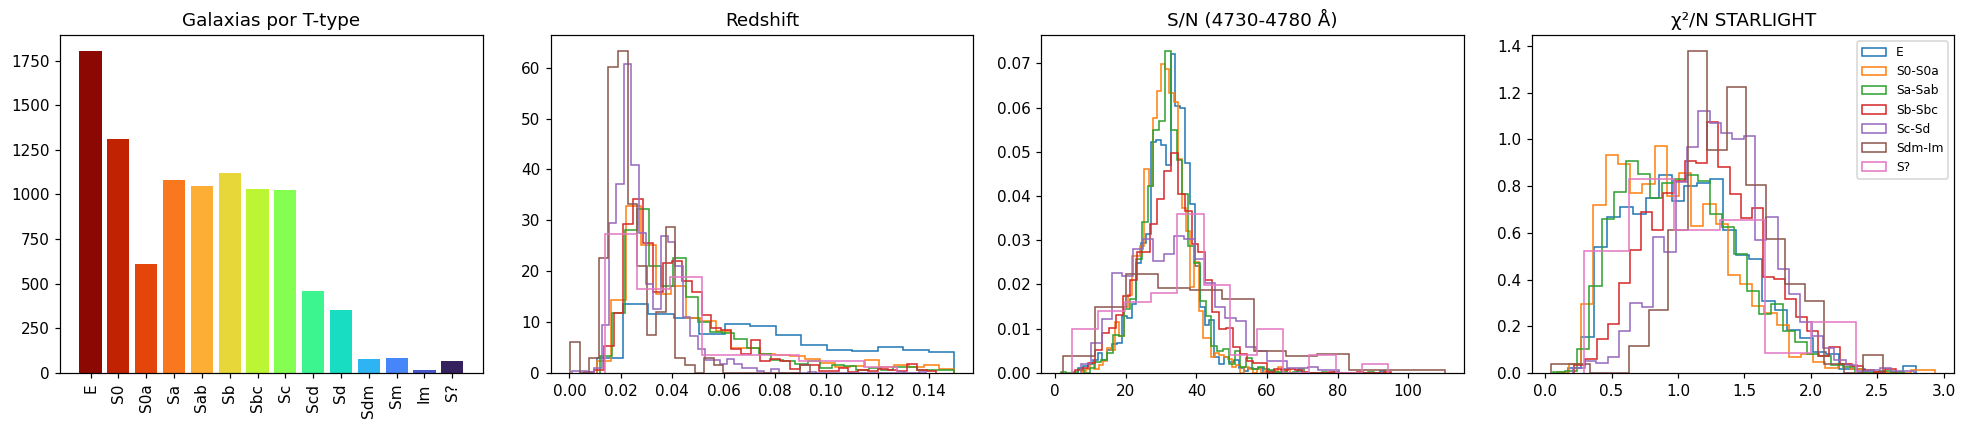

           z      SN   chi2  LogMass
Ttype                               
-5     0.064  32.627  1.056   10.945
-2     0.040  31.597  0.922   10.402
 0     0.036  30.044  0.900   10.183
 1     0.037  31.324  0.954   10.243
 2     0.039  32.329  1.043   10.345
 3     0.039  32.238  1.191   10.209
 4     0.037  33.668  1.240   10.013
 5     0.029  35.184  1.243    9.824
 6     0.025  31.281  1.390    9.380
 7     0.023  27.777  1.374    9.263
 8     0.023  36.917  1.371    9.166
 9     0.021  34.877  1.340    8.940
 10    0.021  39.464  1.541    8.705
 11    0.038  35.932  1.046   10.415


In [14]:
# Revisamos el balance de clases y la calidad de los datos (z, S/N, ajuste de STARLIGHT).
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
conteo = df['Ttype'].value_counts().reindex(ttypes_presentes)
ax[0].bar([NOMBRE_TTYPE[t] for t in ttypes_presentes], conteo, color=[COLOR_TTYPE[t] for t in ttypes_presentes])
ax[0].set_title('Galaxias por T-type'); ax[0].tick_params(axis='x', rotation=90)

for a, col, titulo in zip(ax[1:], ['z', 'SN', 'chi2'], ['Redshift', 'S/N (4730-4780 Å)', 'χ²/N STARLIGHT']):
    for g in ORDEN_GRUPO:
        datos = df.loc[df['grupo'] == g, col].dropna()
        if len(datos) > 3:
            hist_astro(datos, bins='knuth', ax=a, histtype='step', density=True, label=g)  # bins óptimos de Knuth
    a.set_title(titulo)
ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(df.groupby('Ttype')[['z', 'SN', 'chi2', 'LogMass']].median().round(3))

**Conclusión (verifícala con tus resultados):** la muestra no está balanceada. En MaNGA predominan Sb–Sbc y E,
mientras que Sdm–Im son escasas, así que conviene usar métricas balanceadas y agrupar T-types.
Las E/S0 suelen tener mayor S/N (son más brillantes y masivas). Las tardías tienen menor masa y menor S/N, lo que
hace más inciertas sus líneas de absorción. Un χ²/N cercano a 1 en todos los tipos indica que la síntesis es fiable.

rejilla común y normalización

In [15]:
# Para comparar espectros los llevamos a una misma rejilla en reposo y normalizamos
# por la mediana en 5450–5550 Å, una zona sin líneas fuertes.
GRID = np.arange(3500, 8900, 2.0)

def normalizar(wave, flux, ventana=(5450, 5550)):
    m = (wave > ventana[0]) & (wave < ventana[1])
    return flux / np.nanmedian(flux[m])

matriz = np.array([np.interp(GRID, w, normalizar(w, f), left=np.nan, right=np.nan)
                   for w, f in (espectros[n] for n in df.index)])

def marcar_lineas(ax, etiquetas=True):
    """Dibuja líneas de emisión (azul) y de absorción (rojo)."""
    y = ax.get_ylim()[1]
    for grupo in LINEAS_EMISION.values():
        for nom, l in grupo:
            ax.axvline(l, color='tab:blue', ls='--', lw=0.5, alpha=0.6)
            if etiquetas: ax.text(l, y, nom.split('_')[0], rotation=90, fontsize=6, color='tab:blue', va='top')
    for nom, l in LINEAS_ABSORCION.items():
        ax.axvline(l, color='tab:red', ls=':', lw=0.7, alpha=0.7)
        if etiquetas: ax.text(l, y * 0.85, nom.strip(), rotation=90, fontsize=6, color='tab:red', va='top')

espectros agrupados por T-type

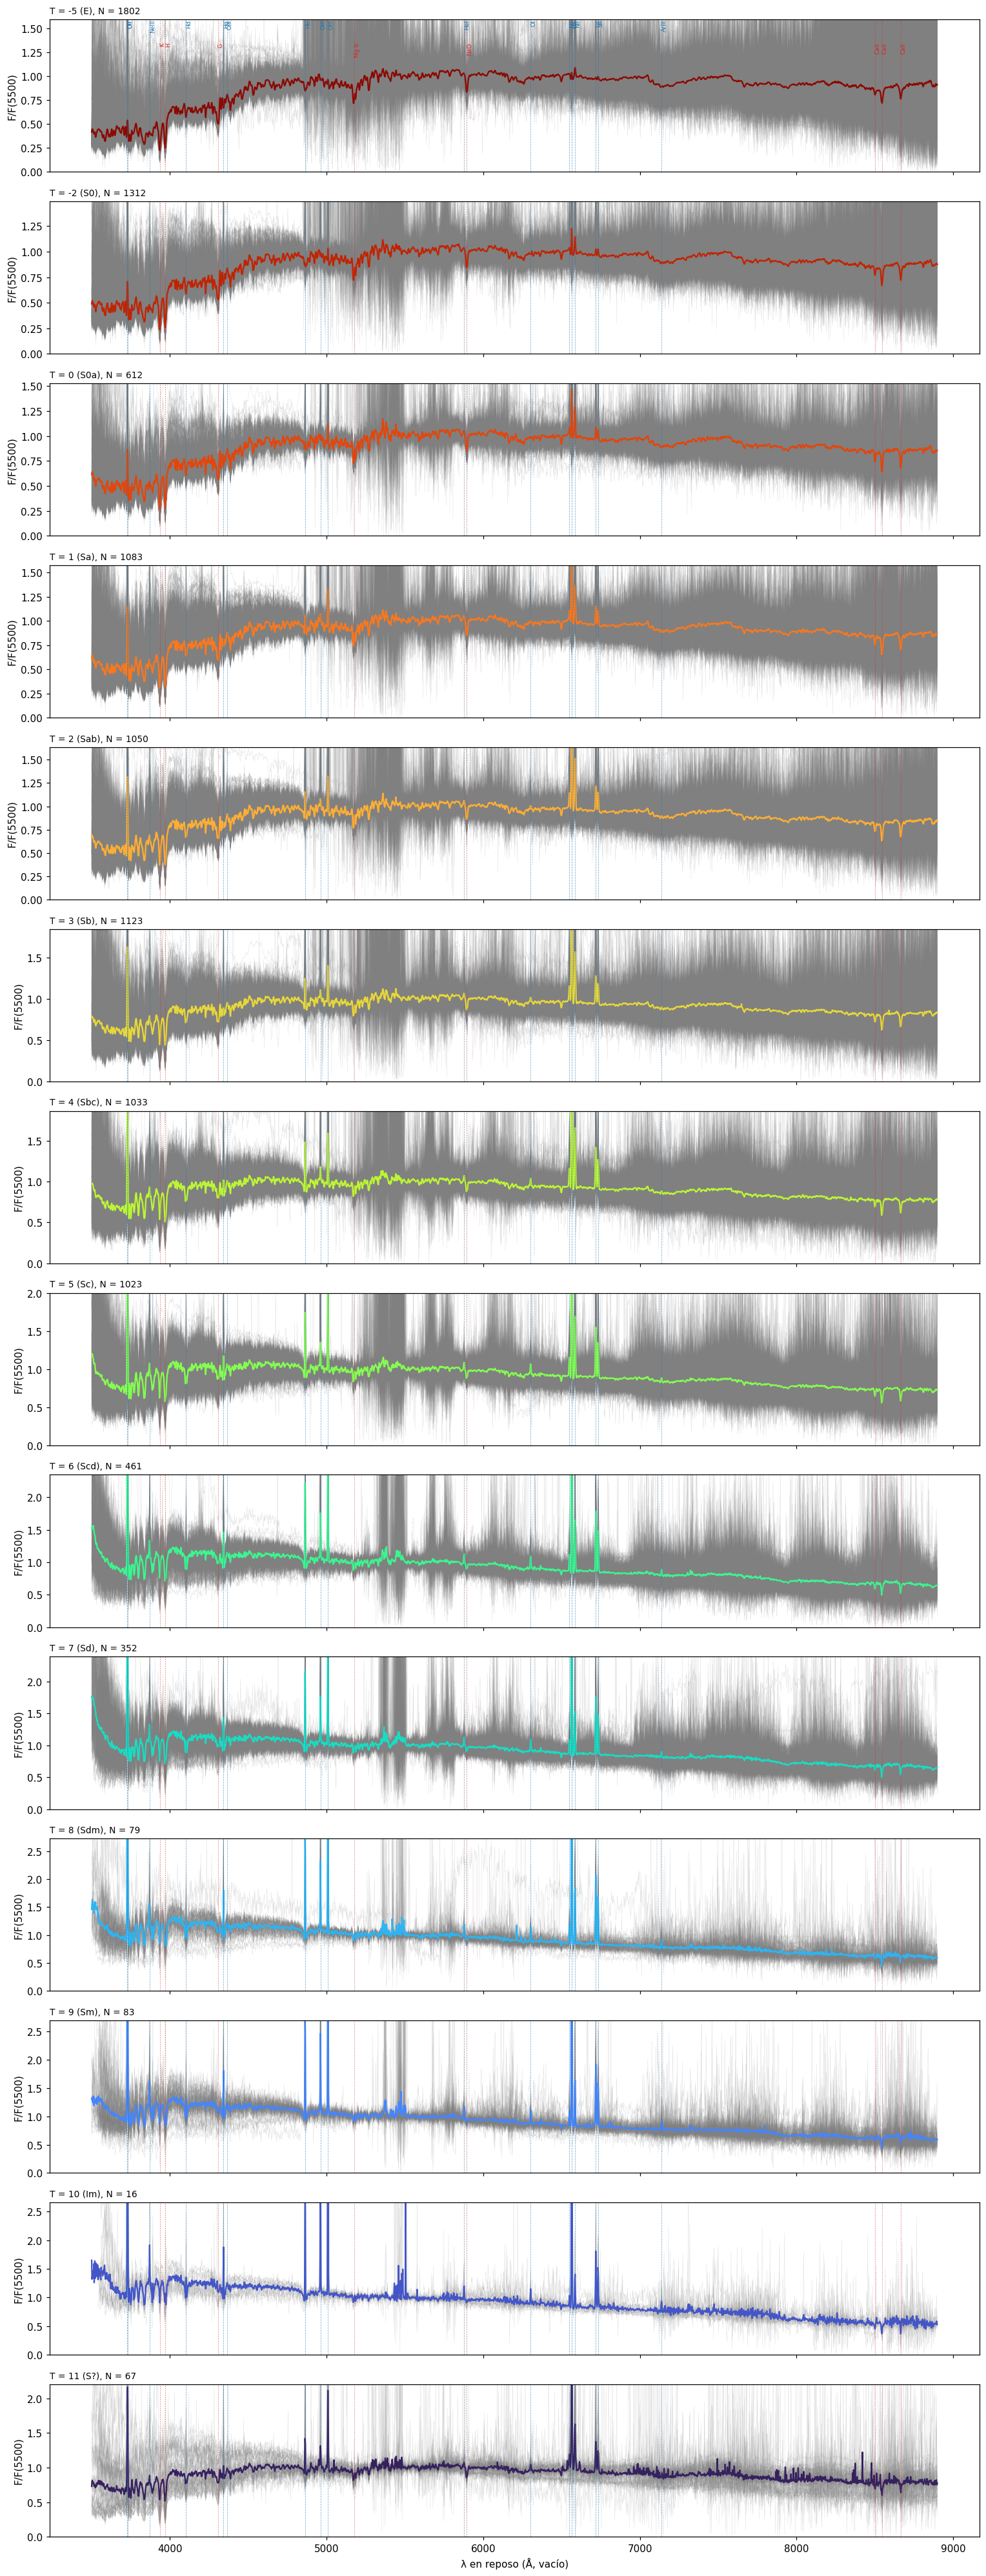

In [16]:
# Un panel por T-type: cada galaxia en gris y el espectro medio en color.
fig, axes = plt.subplots(len(ttypes_presentes), 1, figsize=(14, 2.6 * len(ttypes_presentes)), sharex=True)
for ax, t in zip(np.atleast_1d(axes), ttypes_presentes):
    idx = np.where(df['Ttype'].values == t)[0]
    for i in idx:
        ax.plot(GRID, matriz[i], color='grey', lw=0.3, alpha=0.25)
    ax.plot(GRID, np.nanmean(matriz[idx], axis=0), color=COLOR_TTYPE[t], lw=1.5)
    ax.set_ylim(0, np.nanpercentile(matriz[idx], 99.5) * 1.1)
    ax.set_ylabel('F/F(5500)')
    ax.set_title(f'T = {t} ({NOMBRE_TTYPE[t]}), N = {len(idx)}', fontsize=9, loc='left')
    marcar_lineas(ax, etiquetas=(t == ttypes_presentes[0]))
ax.set_xlabel('λ en reposo (Å, vacío)')
plt.tight_layout(); plt.show()

**Conclusión:** se espera ver la secuencia descrita por Kennicutt (1992). En E/S0 el continuo es rojo,
hay un fuerte quiebre en 4000 Å, Ca II H&K y Mg b profundos y casi no hay emisión. A medida que T crece, el continuo
azul aumenta, el quiebre en 4000 Å se suaviza y crecen Hα, [N II], [S II], [O II] y [O III].
La dispersión entre galaxias (gris) dentro de un mismo T-type puede ser grande en S0–Sab, que combinan
bulbo y disco: la morfología y el espectro no se corresponden 1 a 1.

medio de todos los T-types

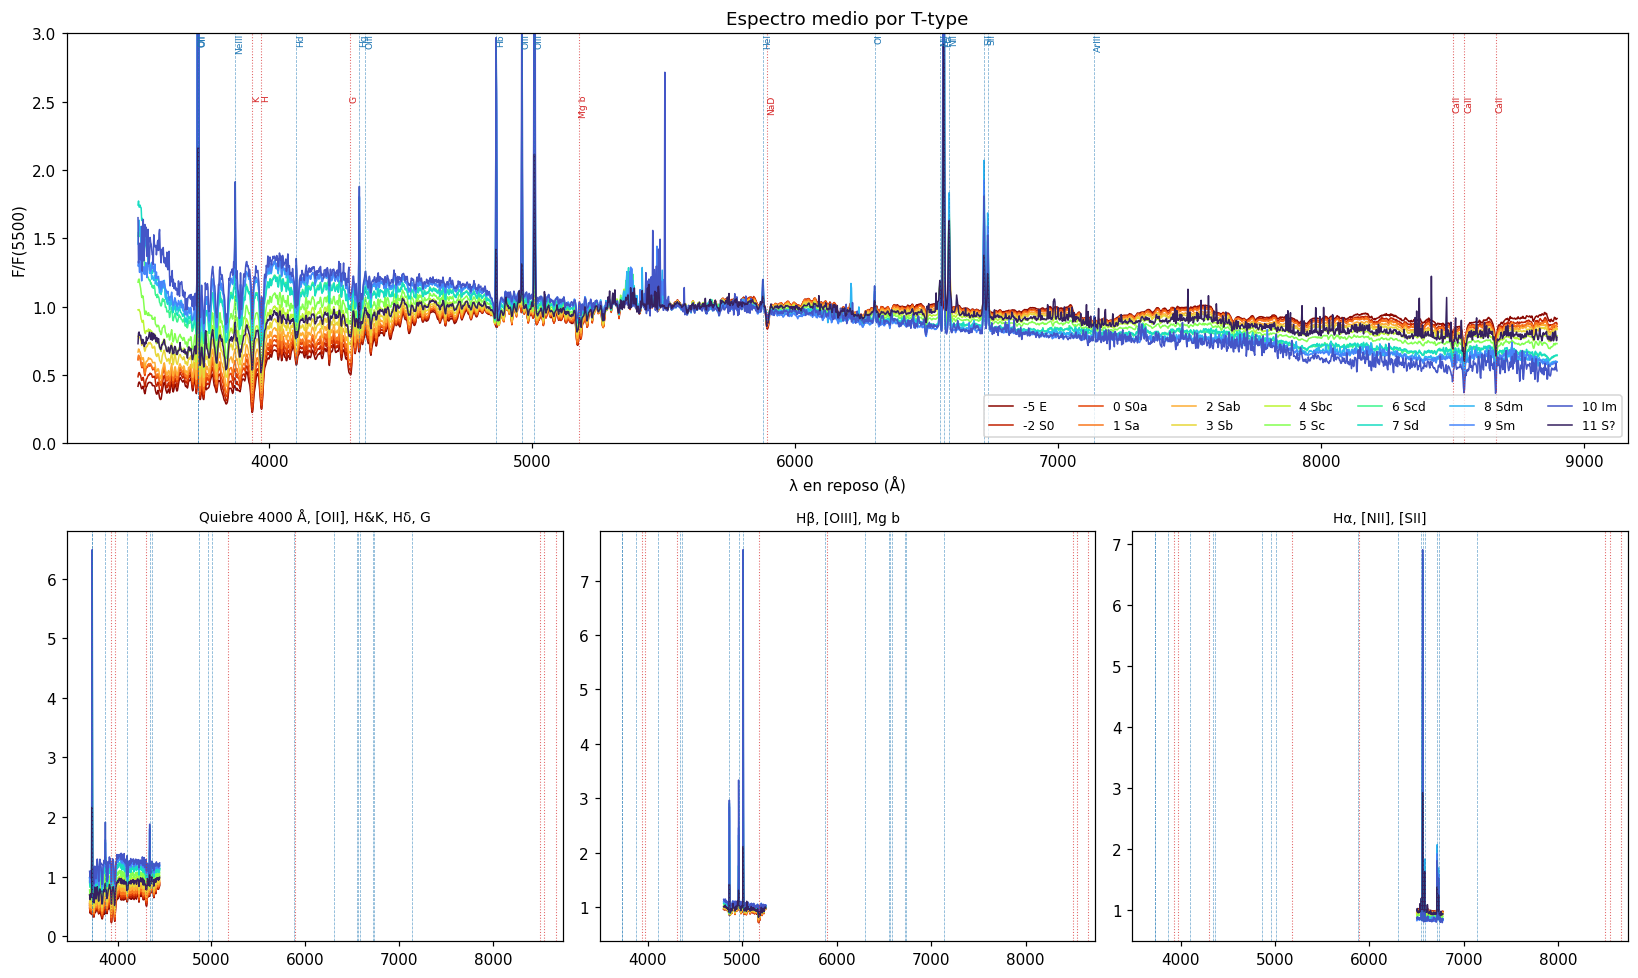

In [17]:
fig = plt.figure(figsize=(15, 9))
ax0 = fig.add_subplot(2, 1, 1)
for t in ttypes_presentes:
    idx = df['Ttype'].values == t
    ax0.plot(GRID, np.nanmean(matriz[idx], axis=0), color=COLOR_TTYPE[t], lw=1, label=f'{t} {NOMBRE_TTYPE[t]}')
ax0.set_ylim(0, 3.0); ax0.set_xlabel('λ en reposo (Å)'); ax0.set_ylabel('F/F(5500)')
ax0.legend(ncol=7, fontsize=8); marcar_lineas(ax0)
ax0.set_title('Espectro medio por T-type')

# Acercamientos a las zonas de diagnóstico
zonas = [(3700, 4450, 'Quiebre 4000 Å, [OII], H&K, Hδ, G'), (4800, 5250, 'Hβ, [OIII], Mg b'),
         (6500, 6780, 'Hα, [NII], [SII]')]
for k, (a, b, titulo) in enumerate(zonas):
    ax = fig.add_subplot(2, 3, 4 + k)
    m = (GRID > a) & (GRID < b)
    for t in ttypes_presentes:
        ax.plot(GRID[m], np.nanmean(matriz[df['Ttype'].values == t][:, m], axis=0), color=COLOR_TTYPE[t], lw=1)
    ax.set_title(titulo, fontsize=9); marcar_lineas(ax, etiquetas=False)
plt.tight_layout(); plt.show()

**Conclusión:** los espectros medios deberían ordenarse casi de forma monótona con T. La pendiente
azul/roja, la amplitud del quiebre en 4000 Å y la intensidad de Hα y [O II] cambian gradualmente de E a Im.
Esto muestra que la morfología es en gran parte una secuencia de historia de formación estelar
(Roberts & Haynes 1994; Blanton & Moustakas 2009). En la zona de Hα+[NII], las tempranas muestran
[NII] ≥ Hα (ionización tipo LINER o estrellas viejas) y las tardías Hα ≫ [NII] (regiones H II).

líneas de emisión

In [18]:
# Las líneas se miden sobre el RESIDUO (observado − sintético de STARLIGHT). Así se elimina la absorción
# estelar subyacente, algo crítico en Hβ, Hγ y Hδ (Kauffmann et al. 2003; Cid Fernandes et al. 2005).
# Se ajustan gaussianas con astropy.modeling; las líneas cercanas se ajustan juntas.
ajustador = fitting.TRFLSQFitter()

def medir_emision(sl, ancho=25):
    esp = sl['espectro']
    v0 = sl['info'].get('v0_min (km/s)', 0.0)
    valido = esp['wei'].values > -2                                # -2 = sin datos
    w = esp['l_obs'].values[valido] / (1 + v0 / C_KMS)            # corrige el pequeño corrimiento v0
    resid = (esp['f_obs'] - esp['f_syn']).values[valido]           # espectro de emisión puro
    cont = esp['f_syn'].values[valido]                             # continuo estelar (para EW)

    res = {}
    for grupo, lineas in LINEAS_EMISION.items():
        centros = [l for _, l in lineas]
        sel = (w > min(centros) - ancho) & (w < max(centros) + ancho)
        nulos = {f'{p}_{nom}': np.nan for nom, _ in lineas for p in ('F', 'EW', 'SN')}
        if sel.sum() < 15:
            res.update(nulos); continue
        x, y = w[sel], resid[sel]

        # Ruido: dispersión robusta del residuo lejos de las líneas
        lejos = np.all([np.abs(x - cc) > 8 for cc in centros], axis=0)
        ruido = sigmaG(y[lejos]) if lejos.sum() > 5 else np.nanstd(y)

        # Modelo = constante + una gaussiana por línea (amplitud ≥ 0, solo emisión)
        modelo = models.Const1D(0.0)
        for cc in centros:
            modelo += models.Gaussian1D(amplitude=max(np.nanmax(y), 1e-3), mean=cc, stddev=2.5,
                                        bounds={'amplitude': (0, None), 'mean': (cc - 4, cc + 4),
                                                'stddev': (0.8, 10)})
        try:
            ajuste = ajustador(modelo, x, y)
        except Exception:
            res.update(nulos); continue

        c_med = np.nanmedian(cont[sel])
        for k, (nom, _) in enumerate(lineas, start=1):          # ajuste[0] es la constante
            g = ajuste[k]
            flujo = g.amplitude.value * g.stddev.value * np.sqrt(2 * np.pi)
            res[f'F_{nom}'] = flujo                              # flujo (unidades normalizadas)
            res[f'EW_{nom}'] = flujo / c_med                     # ancho equivalente (Å, >0 = emisión)
            res[f'SN_{nom}'] = g.amplitude.value / ruido         # S/N aproximada del pico

    # Sumamos el doblete [OII]3726+3729, que no se resuelve
    for p in ('F', 'EW', 'SN'):
        res[f'{p}_OII_3727'] = res[f'{p}_OII_3726'] + res[f'{p}_OII_3729']
    return res

índices de absorción

In [19]:
# Las absorciones se miden sobre el espectro OBSERVADO (.fits.gz en reposo) como pseudo-anchos equivalentes:
# EW = ∫ (1 − F/F_cont) dλ, con F_cont una recta entre los pseudo-continuos azul y rojo (Worthey 1994).
def indice_ew(wave, flux, banda, azul, roja):
    def media(b):
        m = (wave >= b[0]) & (wave <= b[1])
        return np.nanmean(flux[m]), m.sum()
    fa, na = media(azul)
    fr, nr = media(roja)
    m = (wave >= banda[0]) & (wave <= banda[1])
    if na < 2 or nr < 2 or m.sum() < 3:
        return np.nan
    la, lr = np.mean(azul), np.mean(roja)
    cont = fa + (fr - fa) * (wave[m] - la) / (lr - la)
    return trapezoid(1 - flux[m] / cont, wave[m])

def d4000n(wave, flux):
    """Quiebre en 4000 Å angosto (Balogh et al. 1999): cociente de <F_ν> rojo/azul."""
    fnu = flux * wave ** 2                       # F_ν ∝ F_λ λ²
    a = (wave >= D4000_AZUL[0]) & (wave <= D4000_AZUL[1])
    r = (wave >= D4000_ROJO[0]) & (wave <= D4000_ROJO[1])
    return np.nanmean(fnu[r]) / np.nanmean(fnu[a])

medición para todas las galaxias

In [20]:
# Puede tardar (≈11 ajustes por galaxia). Guardamos el resultado en Drive para no repetirlo.
filas = []
for nombre in tqdm(df.index):
    fila = {'name': nombre}
    if nombre in starlight:
        fila.update(medir_emision(starlight[nombre]))
    w, f = espectros[nombre]
    for ind, (b, a, r) in INDICES.items():
        fila[ind] = indice_ew(w, f, b, a, r)
    fila['D4000n'] = d4000n(w, f)
    filas.append(fila)

df = df.join(pd.DataFrame(filas).set_index('name'))
df['CaT'] = df[['CaT1', 'CaT2', 'CaT3']].sum(axis=1, min_count=3)   # triplete del Ca II
df.to_csv(RUTA_RES + 'features_galaxias.csv')
# Para retomar más tarde: df = pd.read_csv(RUTA_RES + 'features_galaxias.csv', index_col='name')

  0%|          | 0/10096 [00:00<?, ?it/s]

cocientes de líneas

In [21]:
SN_MIN = 3
def detectada(*lineas):
    """True si TODAS las líneas tienen S/N ≥ SN_MIN."""
    ok = np.ones(len(df), dtype=bool)
    for l in lineas:
        ok &= (df[f'SN_{l}'] >= SN_MIN).fillna(False).values
    return ok

def log_cociente(num, den):
    return np.where(detectada(num, den), np.log10(df[f'F_{num}'] / df[f'F_{den}']), np.nan)

df['log_NII_Ha']  = log_cociente('NII_6584', 'Ha_6563')
df['log_OIII_Hb'] = log_cociente('OIII_5007', 'Hb_4861')
df['log_OI_Ha']   = log_cociente('OI_6300', 'Ha_6563')
df['log_OIII_OII'] = log_cociente('OIII_5007', 'OII_3727')   # parámetro de ionización (sensible al polvo)
df['log_NII_OII']  = log_cociente('NII_6584', 'OII_3727')    # indicador de metalicidad
# [SII] total
df['F_SII'] = df['F_SII_6717'] + df['F_SII_6731']
ok_sii = detectada('SII_6717', 'SII_6731', 'Ha_6563')
df['log_SII_Ha'] = np.where(ok_sii, np.log10(df['F_SII'] / df['F_Ha_6563']), np.nan)
df['SII_ratio'] = np.where(ok_sii, df['F_SII_6717'] / df['F_SII_6731'], np.nan)  # densidad electrónica

BPT

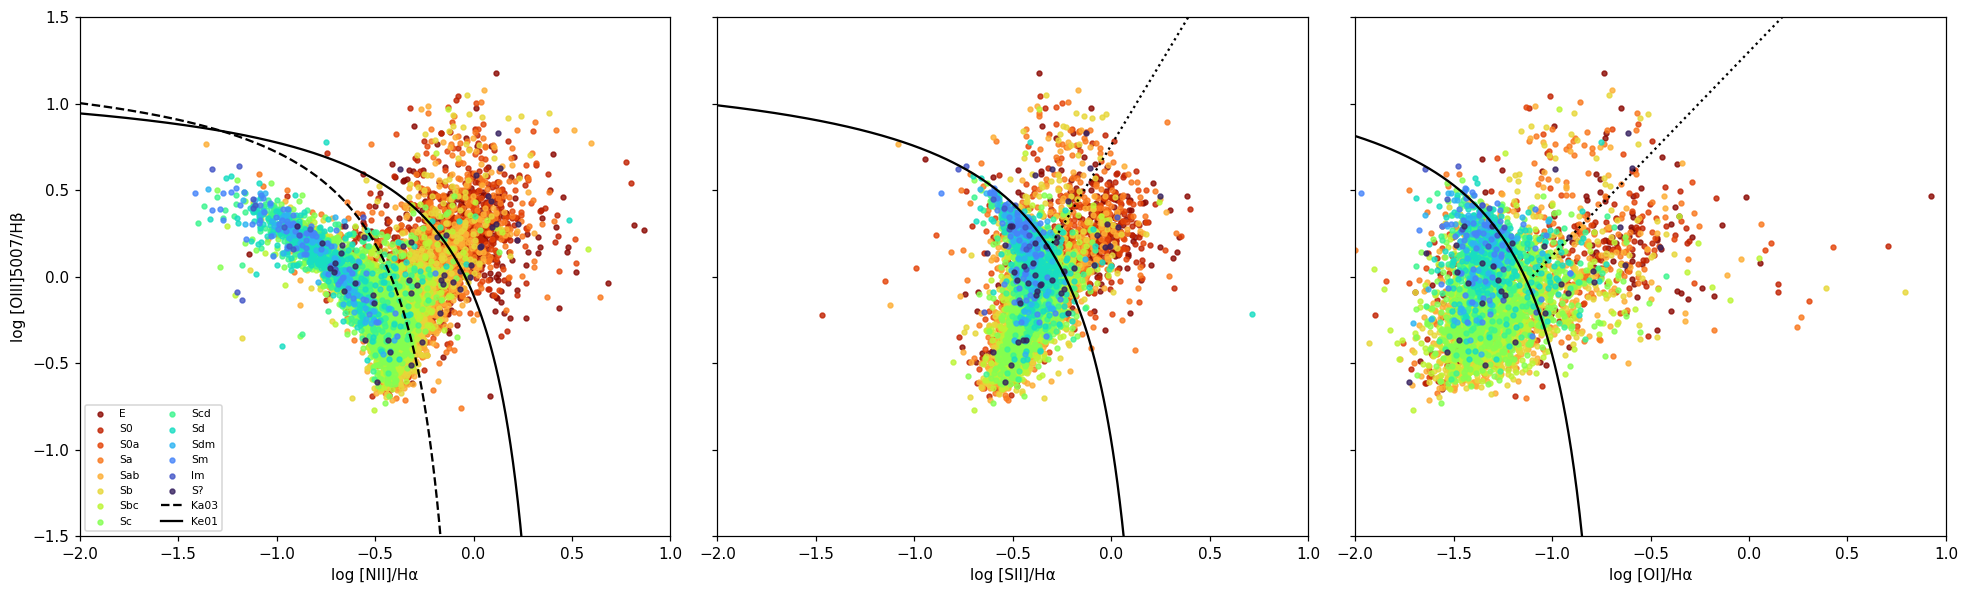

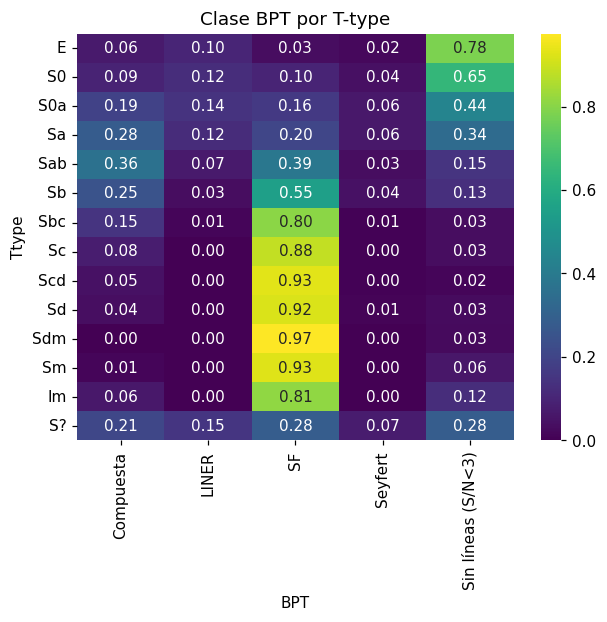

In [22]:
# BPT (Baldwin, Phillips & Terlevich 1981; Veilleux & Osterbrock 1987), con las curvas de
# Kewley et al. 2001 (máximo starburst), Kauffmann et al. 2003 (SF pura) y Kewley et al. 2006 /
# Schawinski et al. 2007 (Seyfert vs LINER).
ka03     = lambda x: 0.61 / (x - 0.05) + 1.30
ke01_nii = lambda x: 0.61 / (x - 0.47) + 1.19
ke01_sii = lambda x: 0.72 / (x - 0.32) + 1.30
ke01_oi  = lambda x: 0.73 / (x + 0.59) + 1.33

def clase_bpt(x, y, x_sii):
    if np.isnan(x) or np.isnan(y):  return 'Sin líneas (S/N<3)'
    if x < 0.05 and y < ka03(x):    return 'SF'
    if x < 0.47 and y < ke01_nii(x): return 'Compuesta'
    if not np.isnan(x_sii):         return 'Seyfert' if y > 1.89 * x_sii + 0.76 else 'LINER'
    return 'Seyfert' if y > 1.05 * x + 0.45 else 'LINER'

df['BPT'] = [clase_bpt(x, y, s) for x, y, s in zip(df['log_NII_Ha'], df['log_OIII_Hb'], df['log_SII_Ha'])]

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
paneles = [('log_NII_Ha', 'log [NII]/Hα'), ('log_SII_Ha', 'log [SII]/Hα'), ('log_OI_Ha', 'log [OI]/Hα')]
for a, (col, etq) in zip(ax, paneles):
    for t in ttypes_presentes:
        s = df[df['Ttype'] == t]
        a.scatter(s[col], s['log_OIII_Hb'], s=10, color=COLOR_TTYPE[t], label=NOMBRE_TTYPE[t], alpha=0.8)
    a.set_xlabel(etq); a.set_xlim(-2.0, 1.0); a.set_ylim(-1.5, 1.5)
x = np.linspace(-2.0, 0.04, 200);  ax[0].plot(x, ka03(x), 'k--', label='Ka03')
x = np.linspace(-2.0, 0.46, 200);  ax[0].plot(x, ke01_nii(x), 'k-', label='Ke01')
x = np.linspace(-2.0, 0.31, 200);  ax[1].plot(x, ke01_sii(x), 'k-')
x = np.linspace(-0.3, 1.0, 50);    ax[1].plot(x, 1.89 * x + 0.76, 'k:')
x = np.linspace(-2.0, -0.60, 200); ax[2].plot(x, ke01_oi(x), 'k-')
x = np.linspace(-1.1, 1.0, 50);    ax[2].plot(x, 1.18 * x + 1.30, 'k:')
ax[0].set_ylabel('log [OIII]5007/Hβ'); ax[0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

# Fracción de cada clase BPT por T-type
tabla_bpt = pd.crosstab(df['Ttype'].map(NOMBRE_TTYPE), df['BPT'], normalize='index').reindex(
    [NOMBRE_TTYPE[t] for t in ttypes_presentes])
sns.heatmap(tabla_bpt, annot=True, fmt='.2f', cmap='viridis'); plt.title('Clase BPT por T-type'); plt.show()

**Conclusión:** la mayoría de las E y S0 deberían caer en "sin líneas" o LINER. Las Sa–Sbc deberían llenar la
zona compuesta y la parte alta de la rama SF (metalicidad alta porque son masivas, Tremonti et al. 2004).
Las Sc–Im deberían concentrarse en la rama SF, con [NII]/Hα bajo y [OIII]/Hβ alto (baja metalicidad).
Las Seyfert son raras en todos los tipos. Ojo: los espectros integran todo el campo de MaNGA, así que un
núcleo activo puede diluirse con las regiones H II del disco.

WHAN

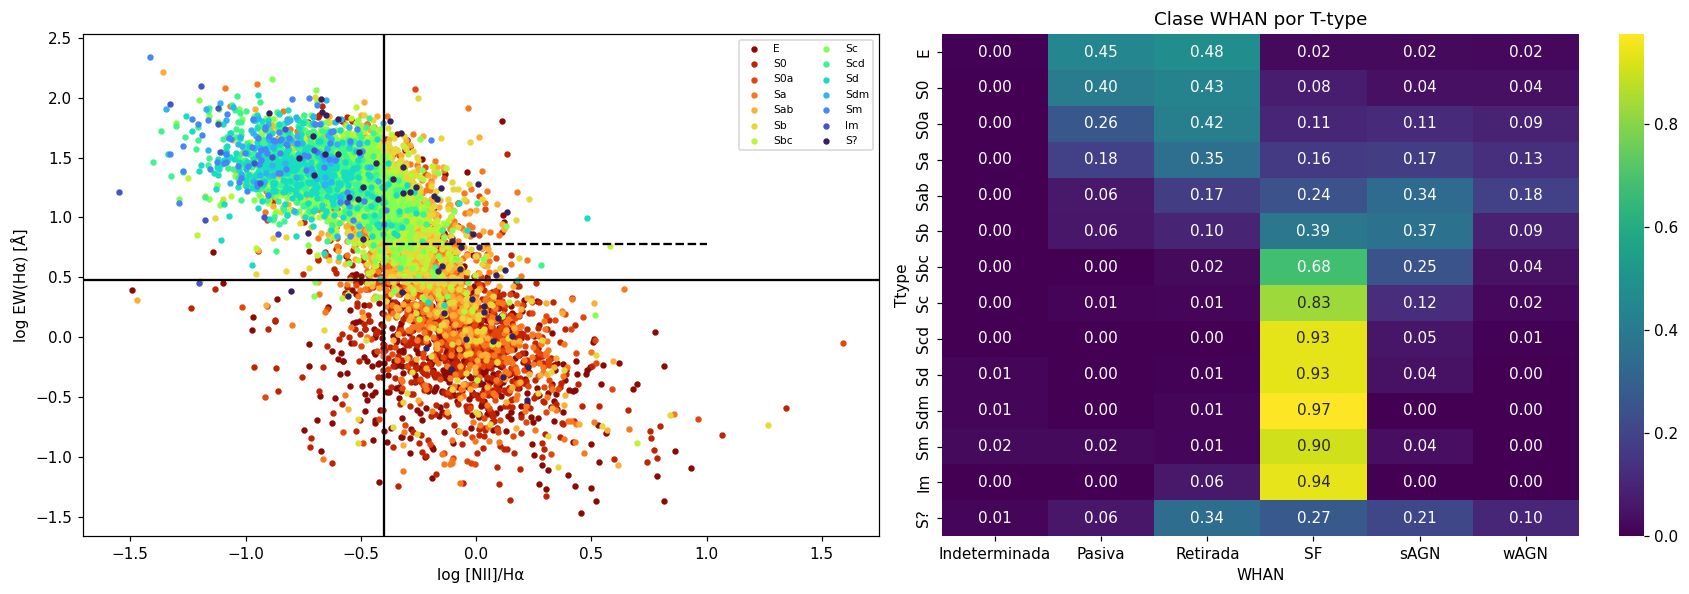

In [23]:
# WHAN (Cid Fernandes et al. 2011) usa EW(Hα) y sí clasifica galaxias de líneas débiles, que el BPT descarta.
# Separa las "retiradas" (ionizadas por estrellas viejas post-AGB; Stasińska et al. 2008) de los AGN reales.
def clase_whan(ew_ha, ew_nii, x):
    if np.isnan(ew_ha):                  return 'Sin datos'
    if ew_ha < 0.5 and ew_nii < 0.5:     return 'Pasiva'
    if ew_ha < 3:                        return 'Retirada'
    if np.isnan(x):                      return 'Indeterminada'
    if x < -0.4:                         return 'SF'
    return 'sAGN' if ew_ha > 6 else 'wAGN'

x_whan = np.where(detectada('Ha_6563') & (df['SN_NII_6584'] >= 2).values,
                  np.log10(df['F_NII_6584'] / df['F_Ha_6563']), np.nan)
df['WHAN'] = [clase_whan(a, b, x) for a, b, x in zip(df['EW_Ha_6563'], df['EW_NII_6584'], x_whan)]

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for t in ttypes_presentes:
    m = (df['Ttype'] == t).values
    ax[0].scatter(x_whan[m], np.log10(df['EW_Ha_6563'].values[m].clip(1e-2)), s=10,
                  color=COLOR_TTYPE[t], label=NOMBRE_TTYPE[t])
ax[0].axvline(-0.4, color='k'); ax[0].axhline(np.log10(3), color='k')
ax[0].plot([-0.4, 1], [np.log10(6)] * 2, 'k--')
ax[0].set_xlabel('log [NII]/Hα'); ax[0].set_ylabel('log EW(Hα) [Å]'); ax[0].legend(fontsize=7, ncol=2)

tabla_whan = pd.crosstab(df['Ttype'].map(NOMBRE_TTYPE), df['WHAN'], normalize='index').reindex(
    [NOMBRE_TTYPE[t] for t in ttypes_presentes])
sns.heatmap(tabla_whan, annot=True, fmt='.2f', cmap='viridis', ax=ax[1]); ax[1].set_title('Clase WHAN por T-type')
plt.tight_layout(); plt.show()

**Conclusión:** WHAN suele separar mejor los tipos tempranos que el BPT. Las E/S0 deberían ser casi todas
"Retiradas/Pasivas" (EW(Hα) < 3 Å), mientras que las espirales tardías tienen EW(Hα) de decenas de Å.
**EW(Hα) es probablemente uno de los mejores discriminadores entre tipos tempranos y tardíos**,
porque mide la tasa de formación estelar específica (Kennicutt 1998).

Balmer

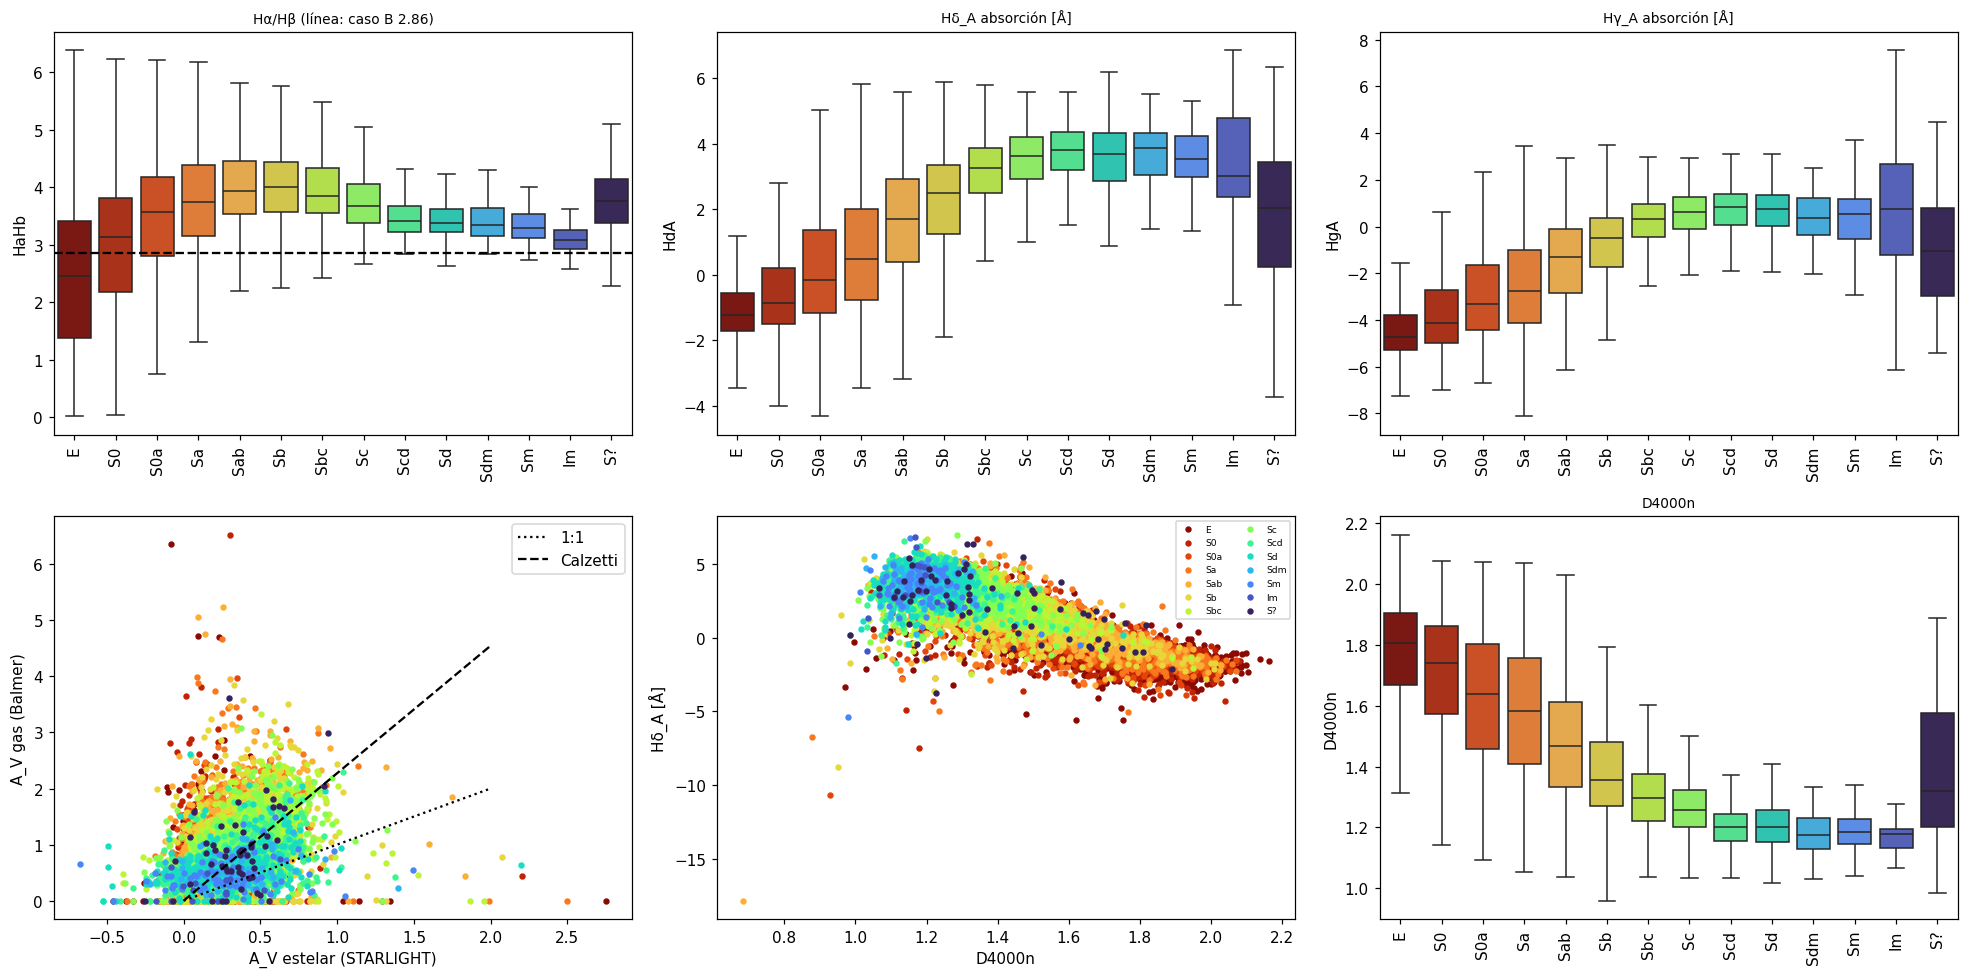

In [24]:
# a) Decremento de Balmer: en caso B (T = 10⁴ K) Hα/Hβ = 2.86 (Osterbrock & Ferland 2006).
#    Un cociente mayor indica polvo. Se usa la ley de CCM89 (k_Hβ = 3.61, k_Hα = 2.53), igual que STARLIGHT.
ok = detectada('Ha_6563', 'Hb_4861')
df['HaHb'] = np.where(ok, df['F_Ha_6563'] / df['F_Hb_4861'], np.nan)
df['AV_gas'] = 3.1 * (2.5 / (3.61 - 2.53) * np.log10(df['HaHb'] / 2.86)).clip(lower=0)
df['HgHb'] = np.where(detectada('Hg_4341', 'Hb_4861'), df['F_Hg_4341'] / df['F_Hb_4861'], np.nan)  # teórico 0.468
df['HdHb'] = np.where(detectada('Hd_4102', 'Hb_4861'), df['F_Hd_4102'] / df['F_Hb_4861'], np.nan)  # teórico 0.259

def caja_por_ttype(col, ax, titulo=None):
    """Boxplot de una variable por T-type (sin outliers, para ver la tendencia)."""
    datos = df[df['Ttype'].isin(ttypes_presentes)]
    sns.boxplot(data=datos, x='Ttype', y=col, hue='Ttype', order=ttypes_presentes,
                palette=COLOR_TTYPE, showfliers=False, legend=False, ax=ax)
    ax.set_xticks(range(len(ttypes_presentes)))
    ax.set_xticklabels([NOMBRE_TTYPE[t] for t in ttypes_presentes], rotation=90)
    ax.set_title(titulo or col, fontsize=9); ax.set_xlabel('')

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
caja_por_ttype('HaHb', ax[0, 0], 'Hα/Hβ (línea: caso B 2.86)'); ax[0, 0].axhline(2.86, color='k', ls='--')
caja_por_ttype('HdA', ax[0, 1], 'Hδ_A absorción [Å]')
caja_por_ttype('HgA', ax[0, 2], 'Hγ_A absorción [Å]')

# b) A_V del gas vs. A_V estelar: se espera A_V,gas ≈ A_V,estelar/0.44 (Calzetti et al. 1994)
for t in ttypes_presentes:
    s = df[df['Ttype'] == t]
    ax[1, 0].scatter(s['AV_estelar'], s['AV_gas'], s=10, color=COLOR_TTYPE[t])
xx = np.linspace(0, 2, 10)
ax[1, 0].plot(xx, xx, 'k:', label='1:1'); ax[1, 0].plot(xx, xx / 0.44, 'k--', label='Calzetti')
ax[1, 0].set_xlabel('A_V estelar (STARLIGHT)'); ax[1, 0].set_ylabel('A_V gas (Balmer)'); ax[1, 0].legend()

# c) D4000n vs Hδ_A (Kauffmann et al. 2003a): historia de formación estelar reciente
for t in ttypes_presentes:
    s = df[df['Ttype'] == t]
    ax[1, 1].scatter(s['D4000n'], s['HdA'], s=10, color=COLOR_TTYPE[t], label=NOMBRE_TTYPE[t])
ax[1, 1].set_xlabel('D4000n'); ax[1, 1].set_ylabel('Hδ_A [Å]'); ax[1, 1].legend(fontsize=6, ncol=2)
caja_por_ttype('D4000n', ax[1, 2], 'D4000n')
plt.tight_layout(); plt.show()

**Conclusión:** en el plano D4000n–Hδ_A se espera una secuencia clara. Las E/S0 tienen D4000n ≈ 1.8–2.0
y Hδ_A < 0 (población vieja). Las Sc–Im tienen D4000n ≈ 1.1–1.4 y Hδ_A ≈ 4–7 Å (estrellas A de 0.1–1 Gyr).
Las galaxias con D4000n bajo y Hδ_A muy alto, pero sin emisión, serían candidatas a post-starburst
(Dressler & Gunn 1983). Hα/Hβ suele ser mayor en espirales masivas e inclinadas (más polvo) que en las Im,
pobres en metales. A_V,gas > A_V,estelar confirma que el gas ionizado está en zonas más polvorientas.

Emision por ttype

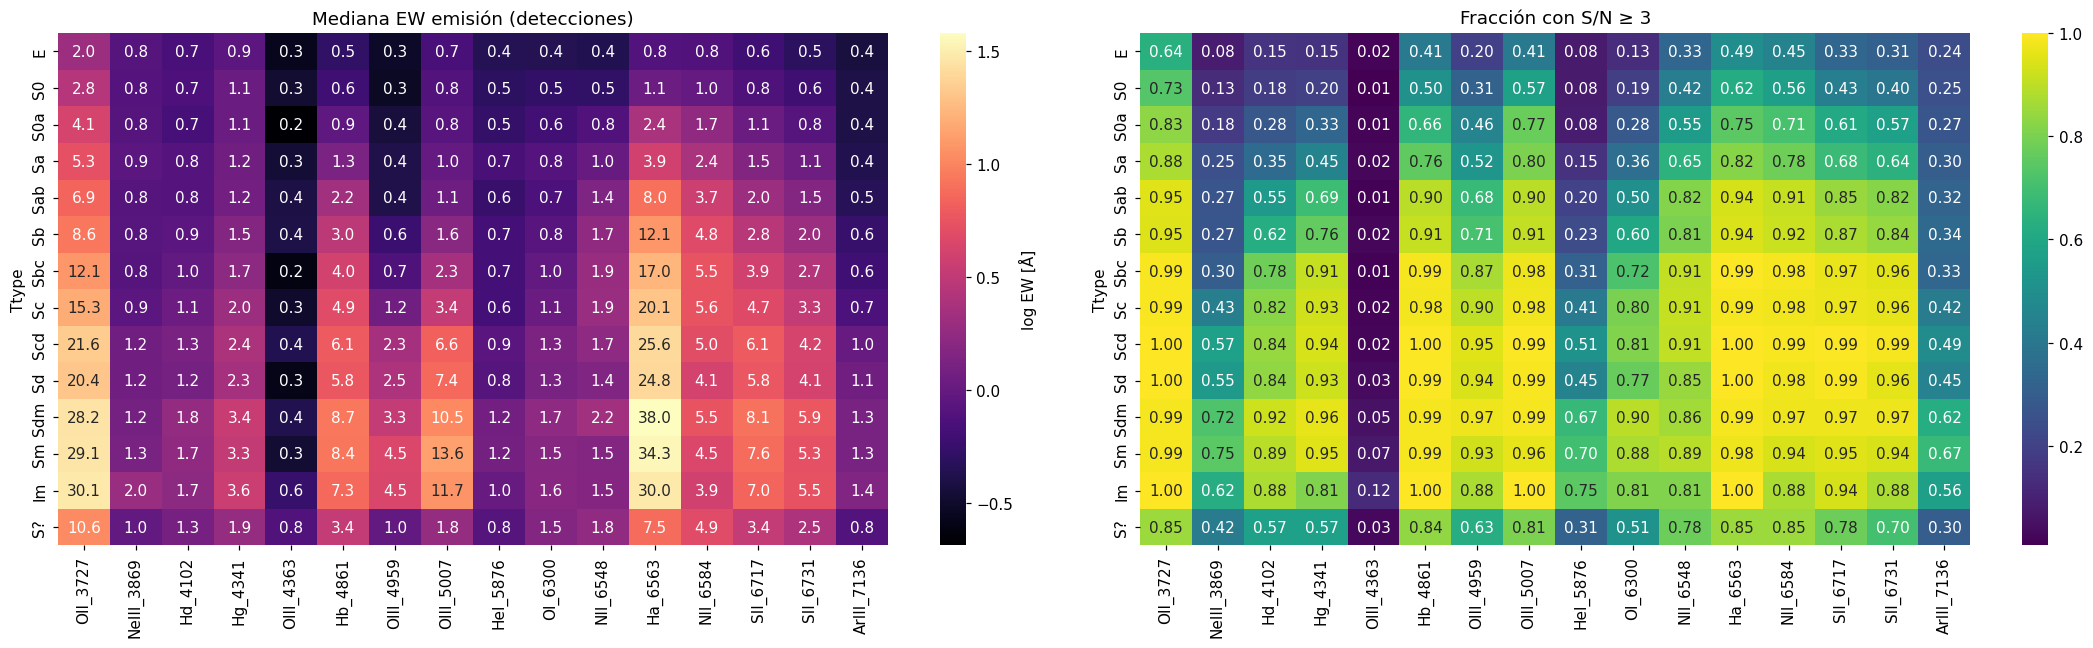

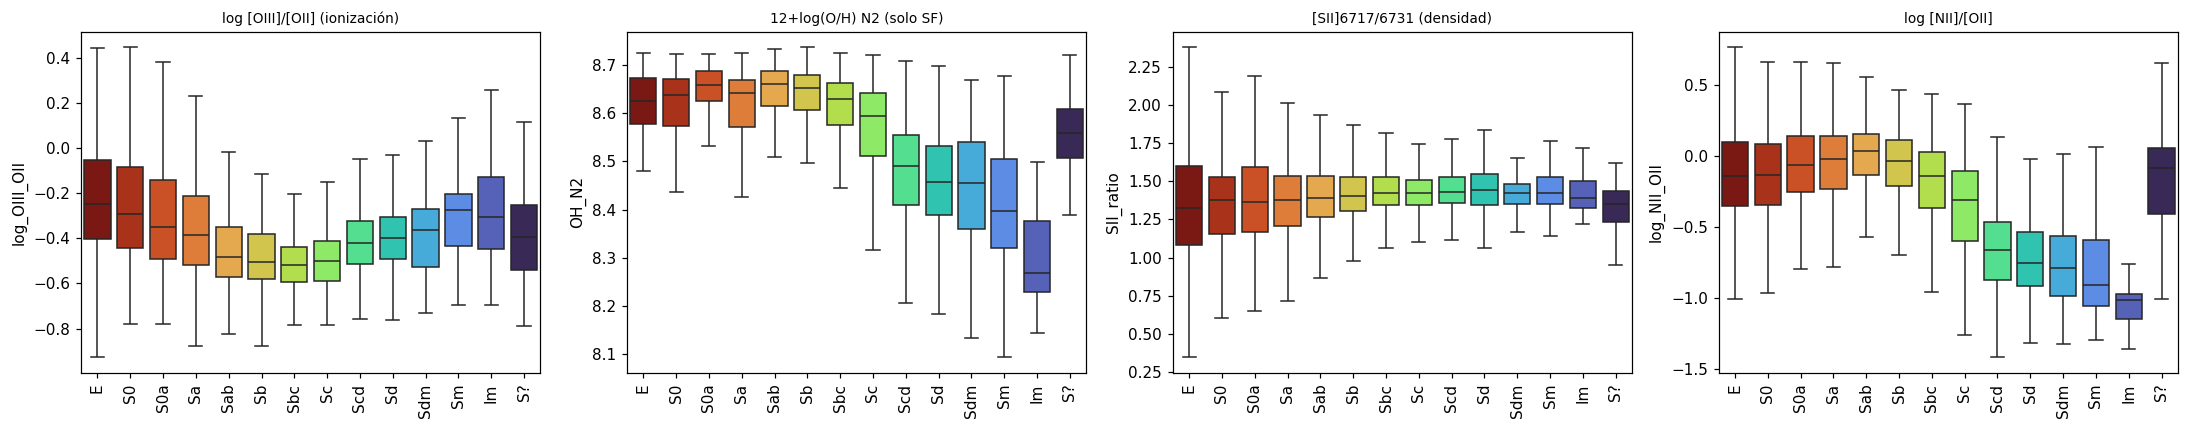

In [25]:
lineas_em = [nom for g in LINEAS_EMISION.values() for nom, _ in g if nom not in ('OII_3726', 'OII_3729')]
lineas_em = ['OII_3727'] + lineas_em
nombres_t = [NOMBRE_TTYPE[t] for t in ttypes_presentes]

# Mediana de EW por T-type (solo detecciones) y fracción de galaxias con S/N ≥ 3
ew_med = pd.DataFrame({l: df[df[f'SN_{l}'] >= SN_MIN].groupby('Ttype')[f'EW_{l}'].median() for l in lineas_em})
frac_det = pd.DataFrame({l: (df[f'SN_{l}'] >= SN_MIN).groupby(df['Ttype']).mean() for l in lineas_em})

fig, ax = plt.subplots(1, 2, figsize=(20, 6))
sns.heatmap(np.log10(ew_med.reindex(ttypes_presentes).clip(lower=0.01)), annot=ew_med.reindex(ttypes_presentes).round(1),
            fmt='', cmap='magma', yticklabels=nombres_t, ax=ax[0], cbar_kws={'label': 'log EW [Å]'})
ax[0].set_title('Mediana EW emisión (detecciones)')
sns.heatmap(frac_det.reindex(ttypes_presentes), annot=True, fmt='.2f', cmap='viridis', yticklabels=nombres_t, ax=ax[1])
ax[1].set_title(f'Fracción con S/N ≥ {SN_MIN}')
plt.tight_layout(); plt.show()

# Diagnósticos físicos adicionales
df['OH_N2'] = np.where(df['BPT'] == 'SF', 8.90 + 0.57 * df['log_NII_Ha'], np.nan)  # Pettini & Pagel 2004 (solo SF)
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
caja_por_ttype('log_OIII_OII', ax[0], 'log [OIII]/[OII] (ionización)')
caja_por_ttype('OH_N2', ax[1], '12+log(O/H) N2 (solo SF)')
caja_por_ttype('SII_ratio', ax[2], '[SII]6717/6731 (densidad)')
caja_por_ttype('log_NII_OII', ax[3], 'log [NII]/[OII]')
plt.tight_layout(); plt.show()

**Conclusión:** la fracción de detección de Hα, Hβ, [OII] y [SII] debería subir de forma marcada de E a Sc,
igual que sus EW medianos, mientras que [OIII]4363, [ArIII] y HeI solo se detectan en tardías con buen S/N.
La metalicidad N2 debería bajar hacia Sdm–Im, que son menos masivas (relación masa–metalicidad).
[SII]6717/6731 ≈ 1.3–1.4 (bajo límite de baja densidad, < 100 cm⁻³) es típico de discos y no distingue tipos.
Las líneas de alta ionización ([OIII]4363, [ArIII], HeI) sirven poco como features: casi siempre faltan.

absorcion por ttype

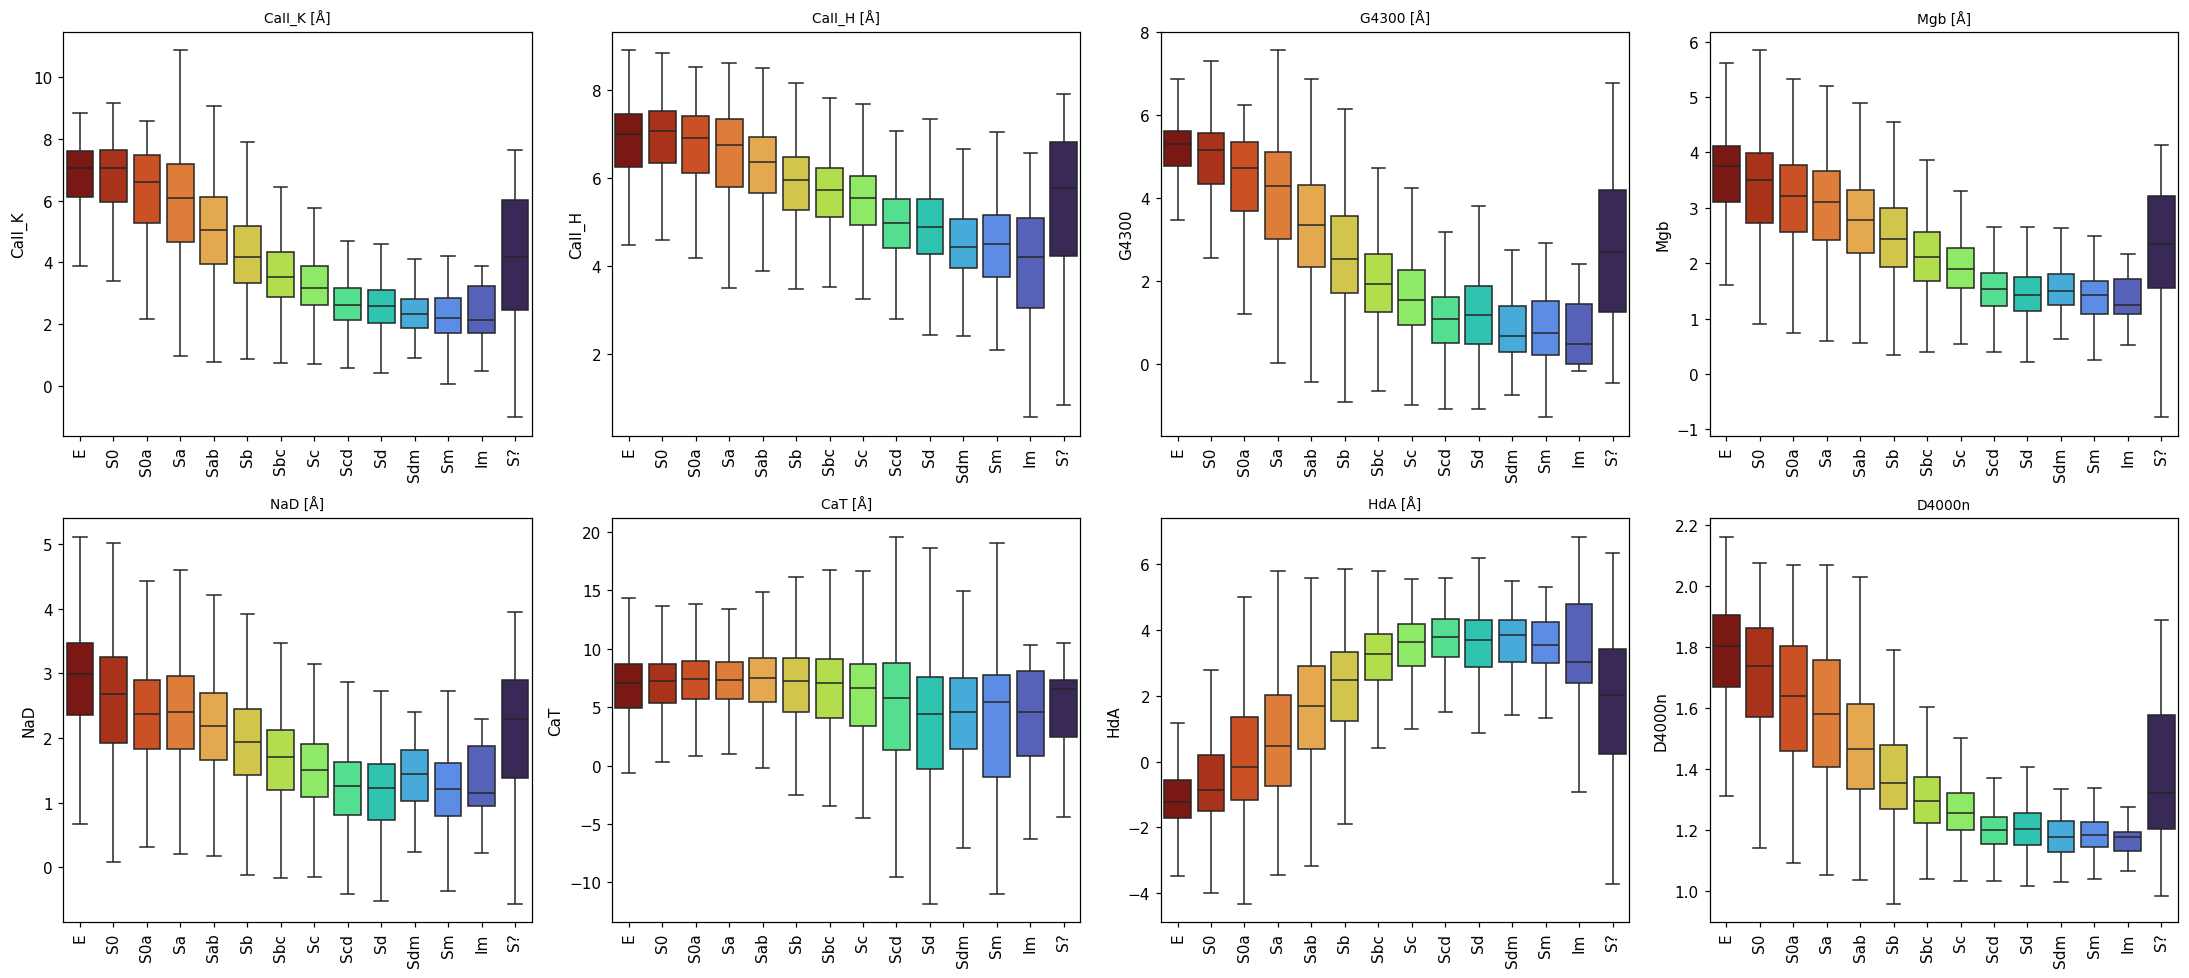

      CaII_K       CaII_H        G4300          Mgb          NaD          CaT  \
      median  sigG median  sigG median  sigG median  sigG median  sigG median   
Ttype                                                                           
-5      7.07  1.10   7.01  0.88   5.31  0.64   3.76  0.75   2.99  0.83   7.03   
-2      7.04  1.26   7.07  0.87   5.16  0.90   3.50  0.93   2.68  0.99   7.24   
 0      6.60  1.64   6.91  0.97   4.74  1.24   3.21  0.91   2.36  0.79   7.45   
 1      6.07  1.86   6.75  1.15   4.29  1.55   3.10  0.92   2.41  0.84   7.36   
 2      5.06  1.61   6.36  0.94   3.36  1.46   2.78  0.84   2.19  0.76   7.49   
 3      4.18  1.36   5.96  0.89   2.53  1.37   2.43  0.79   1.94  0.76   7.26   
 4      3.54  1.08   5.74  0.83   1.93  1.04   2.11  0.65   1.71  0.68   7.09   
 5      3.19  0.94   5.55  0.83   1.53  0.98   1.90  0.52   1.51  0.61   6.64   
 6      2.62  0.77   4.99  0.82   1.09  0.82   1.54  0.43   1.26  0.61   5.78   
 7      2.59  0.80   4.89  0

In [26]:
fig, ax = plt.subplots(2, 4, figsize=(20, 9))
for a, col in zip(ax.ravel(), ['CaII_K', 'CaII_H', 'G4300', 'Mgb', 'NaD', 'CaT', 'HdA', 'D4000n']):
    caja_por_ttype(col, a, f'{col} [Å]' if col != 'D4000n' else col)
plt.tight_layout(); plt.show()

# Resumen robusto: mediana y σ_G (astroML) por T-type
def sigG(s):
    s = s.dropna(); return sigmaG(s) if len(s) > 2 else np.nan
cols = ['CaII_K', 'CaII_H', 'G4300', 'Mgb', 'NaD', 'CaT', 'HdA', 'HgA', 'D4000n']
print(df.groupby('Ttype')[cols].agg(['median', sigG]).round(2))

**Conclusión:** Mg b, banda G, Ca II K y D4000n deberían disminuir de E a Im. Trazan estrellas frías, viejas
y ricas en metales, y además Mg b correlaciona con σ y la masa (Trager et al. 1998). Hδ_A y Hγ_A siguen la
tendencia opuesta. NaD tiene una componente interestelar (absorbe el gas frío del disco), así que puede ser alto
también en espirales polvorientas e inclinadas: no es un indicador estelar puro (Concas et al. 2019).
Ca II H se mezcla con Hε y el CaT depende poco de la edad, así que se espera que separen peor.

propiedades de STARLIGHT

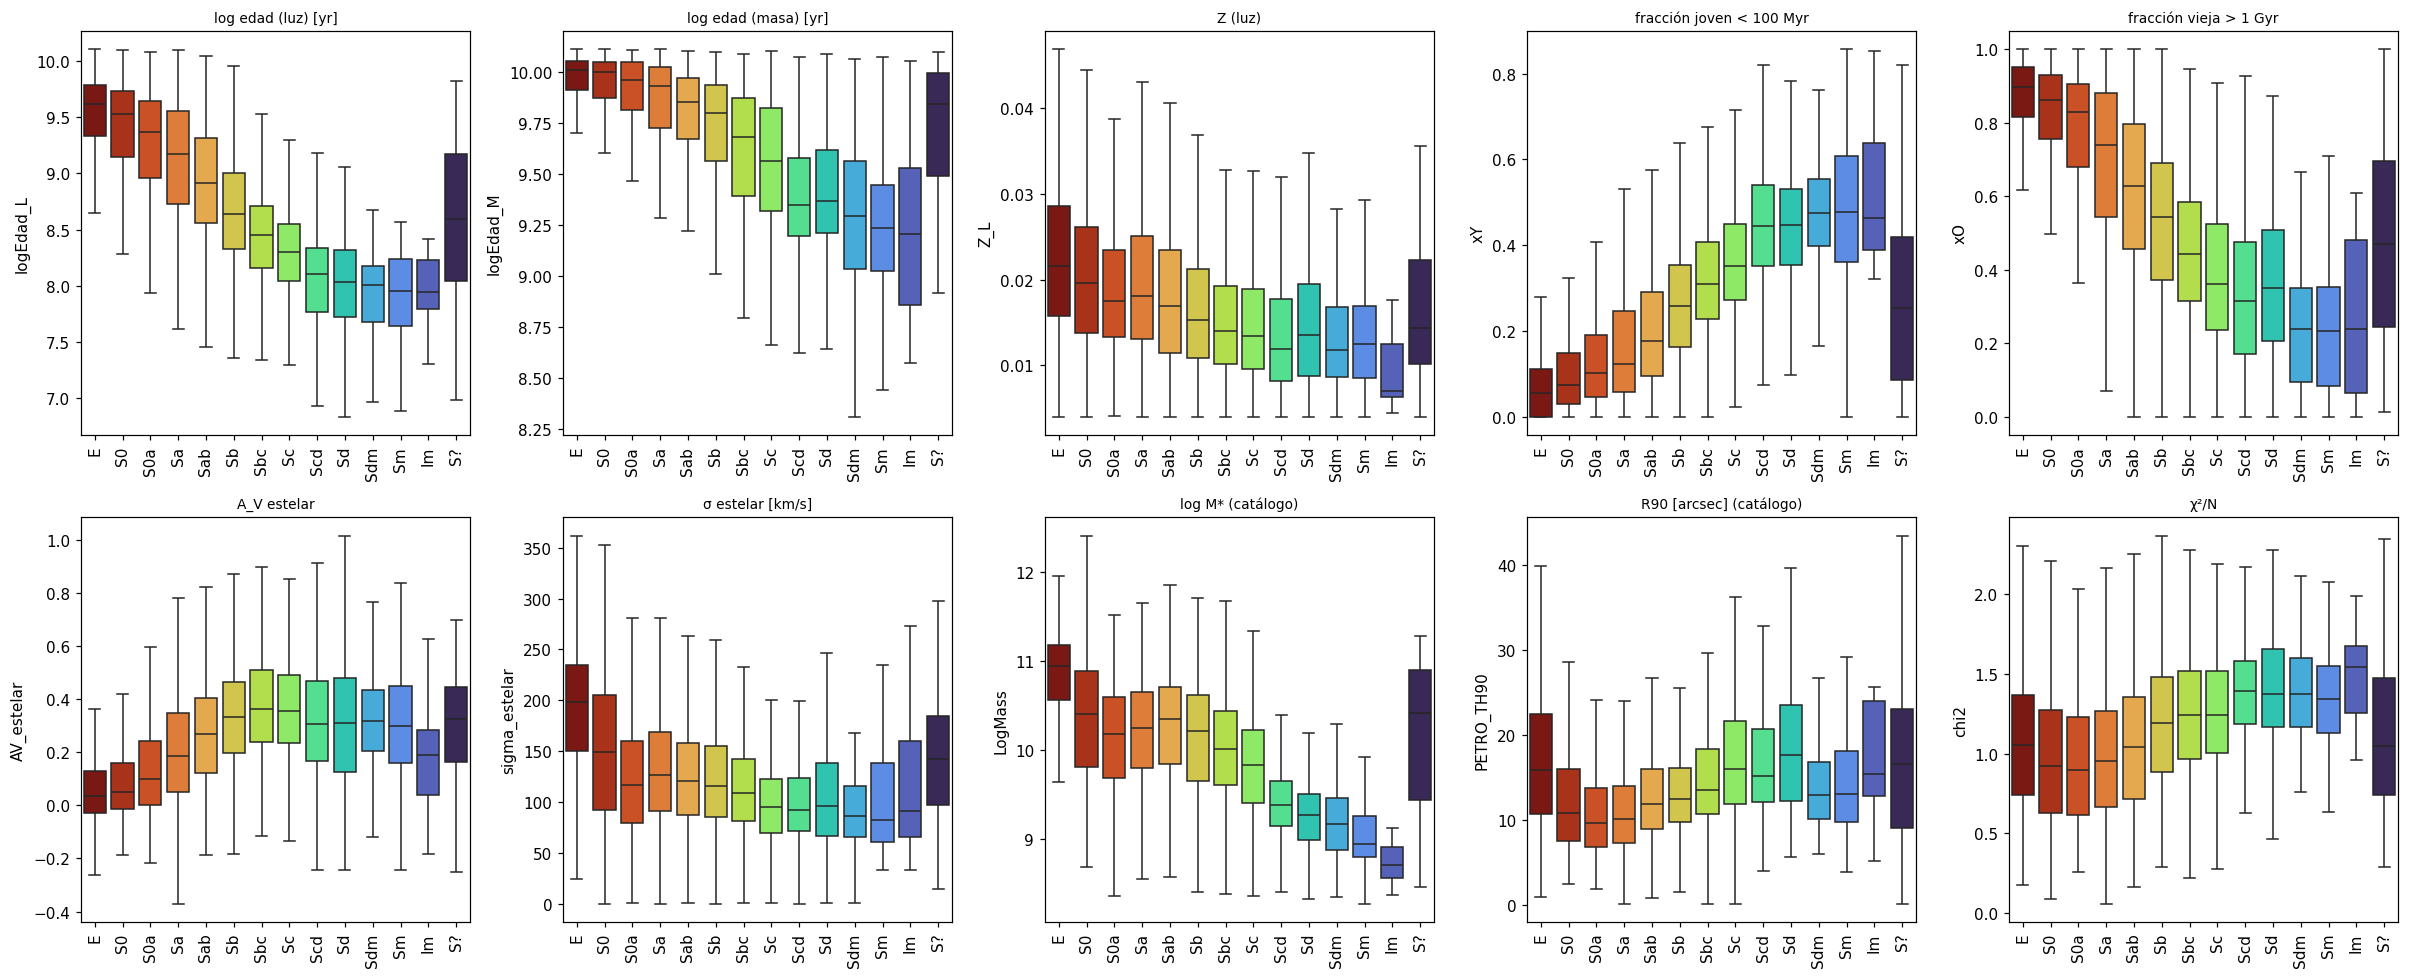

In [27]:
fig, ax = plt.subplots(2, 5, figsize=(22, 9))
paneles = [('logEdad_L', 'log edad (luz) [yr]'), ('logEdad_M', 'log edad (masa) [yr]'), ('Z_L', 'Z (luz)'),
           ('xY', 'fracción joven < 100 Myr'), ('xO', 'fracción vieja > 1 Gyr'), ('AV_estelar', 'A_V estelar'),
           ('sigma_estelar', 'σ estelar [km/s]'), ('LogMass', 'log M* (catálogo)'),
           ('PETRO_TH90', 'R90 [arcsec] (catálogo)'), ('chi2', 'χ²/N')]
for a, (col, t) in zip(ax.ravel(), paneles):
    caja_por_ttype(col, a, t)
plt.tight_layout(); plt.show()

**Conclusión:** la edad pesada por luz debería ser la propiedad más sensible al tipo, porque la luz está dominada
por las estrellas jóvenes. La edad pesada por masa varía menos: casi todas las galaxias formaron la mayor parte
de su masa temprano (downsizing; Cid Fernandes et al. 2005; Pérez et al. 2013). xY sube y xO baja hacia
los tipos tardíos. σ estelar y LogMass son mayores en E/S0 (bulbos dinámicamente calientes). Nota: σ de
STARLIGHT no corrige del todo la resolución instrumental de MaNGA (~70 km/s), así que valores < 70 km/s son poco fiables.

PCA

Varianza explicada: [0.545 0.073 0.041 0.02  0.012]


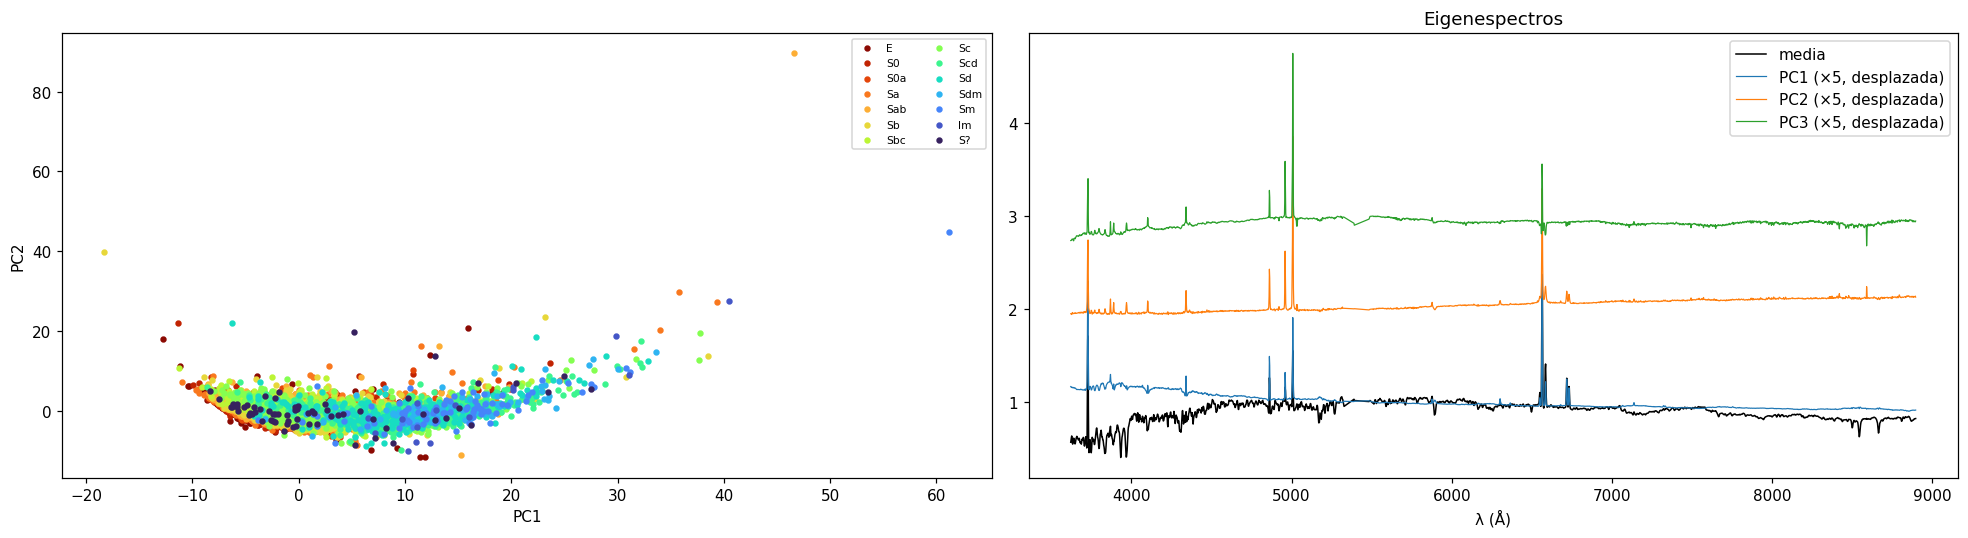

In [28]:
# PCA de espectros (Connolly et al. 1995; Yip et al. 2004; Ivezić et al. 2014, cap. 7):
# las primeras componentes resumen la forma del continuo y las líneas.
filas_ok = np.isfinite(matriz).mean(axis=1) > 0.8          # descartamos espectros con muchos NaN
cols_ok = np.all(np.isfinite(matriz[filas_ok]), axis=0)     # rango cubierto por todos
X_esp = matriz[filas_ok][:, cols_ok]

pca = PCA(n_components=5).fit(X_esp)
proy = pca.transform(X_esp)
for k in range(3):
    df.loc[df.index[filas_ok], f'PC{k + 1}'] = proy[:, k]
print('Varianza explicada:', pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for t in ttypes_presentes:
    m = df['Ttype'].values[filas_ok] == t
    ax[0].scatter(proy[m, 0], proy[m, 1], s=10, color=COLOR_TTYPE[t], label=NOMBRE_TTYPE[t])
ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); ax[0].legend(fontsize=7, ncol=2)
ax[1].plot(GRID[cols_ok], pca.mean_, 'k', lw=1, label='media')
for k in range(3):
    ax[1].plot(GRID[cols_ok], pca.components_[k] * 5 + 1 + k, lw=0.8, label=f'PC{k + 1} (×5, desplazada)')
ax[1].legend(); ax[1].set_xlabel('λ (Å)'); ax[1].set_title('Eigenespectros')
plt.tight_layout(); plt.show()

**Conclusión:** se espera que PC1 (normalmente más de 80 % de la varianza) represente la pendiente
del continuo y el quiebre en 4000 Å, es decir, la edad, y que ordene las galaxias de E a Im.
PC2 suele capturar las líneas de emisión. Si en PC1–PC2 los T-types forman una secuencia continua y no grupos
separados, confirma que la morfología es un continuo y que los tipos vecinos (p. ej. Sb vs Sbc) serán difíciles
de distinguir solo con el espectro.

Features

               frac_valida         H    p  epsilon2  rho_T  info_mutua  \
feature                                                                  
HdA                  1.000  5870.501  0.0     0.585  0.759       0.385   
HgA                  1.000  5732.630  0.0     0.571  0.749       0.383   
G4300                1.000  5667.665  0.0     0.565 -0.746       0.376   
D4000n               1.000  5662.891  0.0     0.564 -0.747       0.378   
EW_Ha_6563           1.000  5621.604  0.0     0.560  0.743       0.400   
EW_SII_6717          1.000  5530.606  0.0     0.551  0.737       0.372   
PC1                  1.000  5416.021  0.0     0.540  0.730       0.365   
CaII_K               1.000  5288.710  0.0     0.527 -0.713       0.348   
logEdad_L            1.000  5266.895  0.0     0.525 -0.719       0.354   
EW_SII_6731          1.000  5258.894  0.0     0.524  0.718       0.354   
EW_Hb_4861           1.000  5239.036  0.0     0.522  0.713       0.354   
EW_OII_3727          1.000  5218.331  

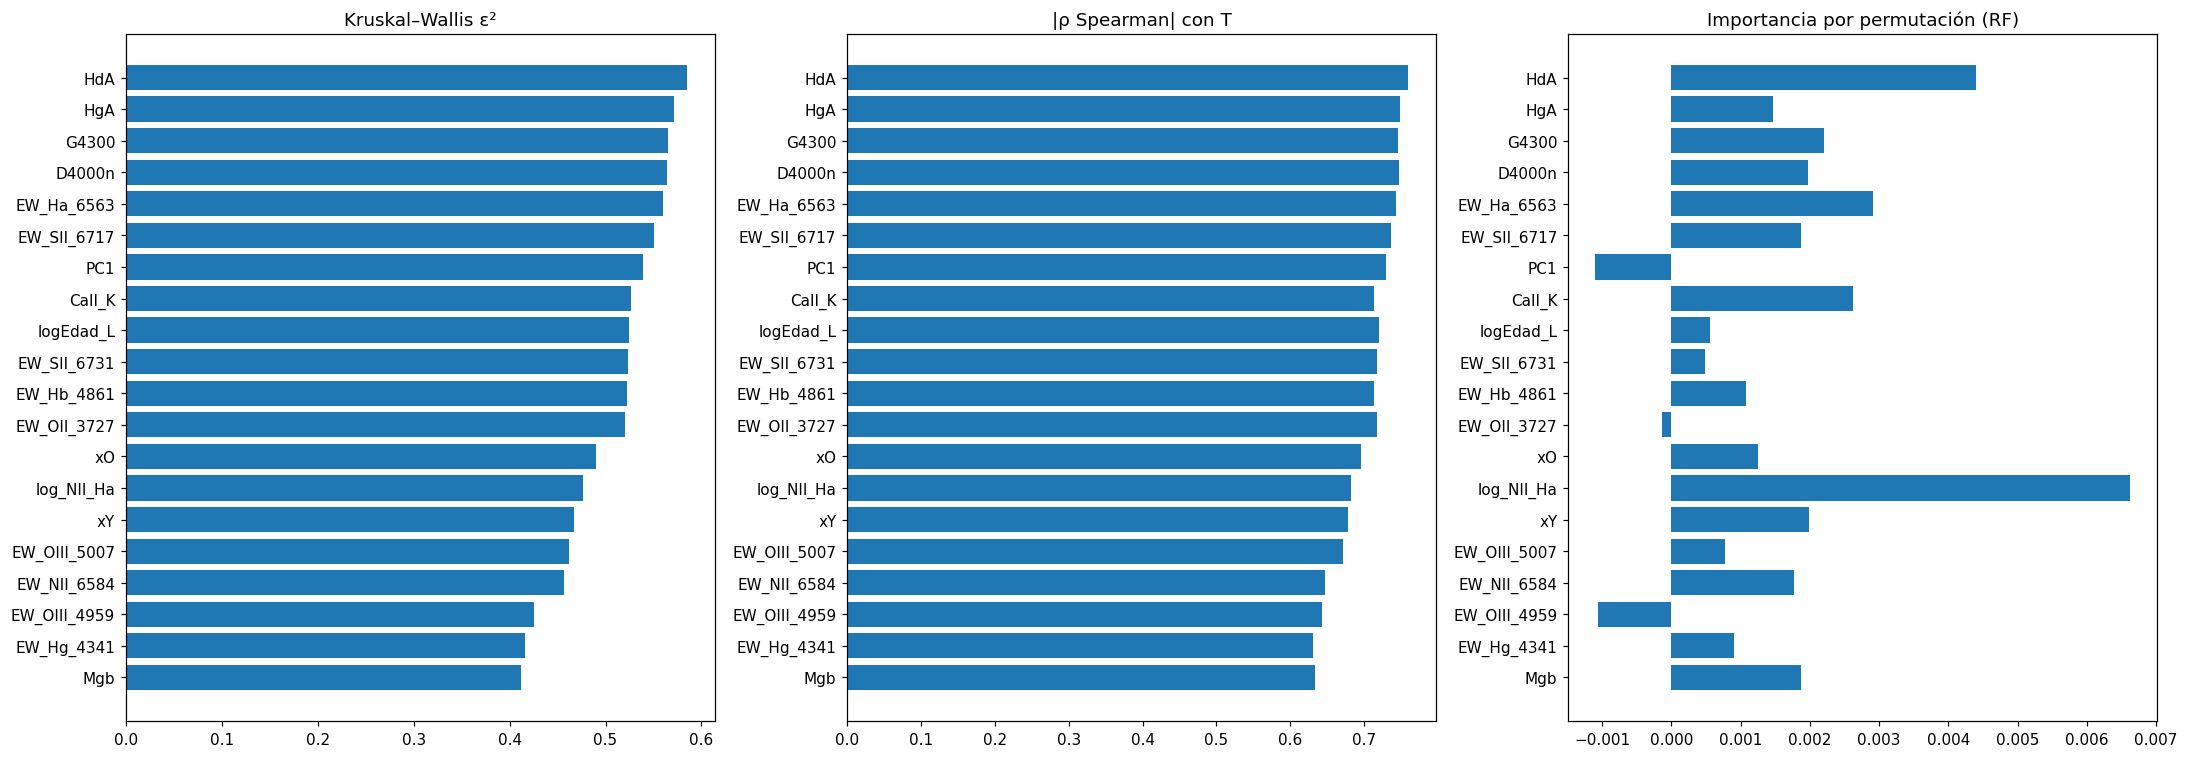

In [29]:
# Excluimos T=11 (sin subtipo) porque no es ordinal con el resto.
features = (['EW_' + l for l in lineas_em] +
            ['CaII_K', 'CaII_H', 'G4300', 'Mgb', 'NaD', 'CaT', 'HdA', 'HgA', 'D4000n'] +
            ['log_NII_Ha', 'log_OIII_Hb', 'log_SII_Ha', 'HaHb'] +
            ['logEdad_L', 'logEdad_M', 'Z_L', 'Z_M', 'xY', 'xI', 'xO', 'AV_estelar', 'sigma_estelar'] +
            ['PC1', 'PC2', 'PC3'] +
            ['LogMass', 'PETRO_TH90'])          # complementos del catálogo
d = df[df['Ttype'] != 11]

# 1) Kruskal–Wallis: ¿difieren las distribuciones entre T-types? Tamaño del efecto ε² (Tomczak & Tomczak 2014)
# 2) Spearman: ¿hay tendencia monótona con T?
res = []
for f in features:
    s = d[[f, 'Ttype']].dropna()
    grupos = [g[f].values for _, g in s.groupby('Ttype') if len(g) >= 3]
    if len(grupos) < 2:
        continue
    H, p = kruskal(*grupos)
    k, n = len(grupos), sum(len(g) for g in grupos)
    rho, _ = spearmanr(s[f], s['Ttype'])
    res.append({'feature': f, 'frac_valida': len(s) / len(d), 'H': H, 'p': p,
                'epsilon2': (H - k + 1) / (n - k), 'rho_T': rho})
ranking = pd.DataFrame(res).set_index('feature')

# 3) Información mutua y 4) importancia por permutación de un Random Forest (grupos amplios)
X = d[ranking.index].fillna(d[ranking.index].median())
y = d['Ttype'].map(grupo_amplio)
ranking['info_mutua'] = mutual_info_classif(X, y, random_state=0)

rf = RandomForestClassifier(n_estimators=500, class_weight='balanced', random_state=0, n_jobs=-1)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
rf.fit(X_tr, y_tr)
perm = permutation_importance(rf, X_te, y_te, n_repeats=20, random_state=0, scoring='balanced_accuracy')
ranking['perm_importancia'] = perm.importances_mean

ranking = ranking.sort_values('epsilon2', ascending=False)
ranking.to_csv(RUTA_RES + 'ranking_features.csv')
print(ranking.round(3))

fig, ax = plt.subplots(1, 3, figsize=(20, 7))
top = ranking.head(20)
ax[0].barh(top.index[::-1], top['epsilon2'][::-1]); ax[0].set_title('Kruskal–Wallis ε²')
ax[1].barh(top.index[::-1], top['rho_T'][::-1].abs()); ax[1].set_title('|ρ Spearman| con T')
ax[2].barh(top.index[::-1], top['perm_importancia'][::-1]); ax[2].set_title('Importancia por permutación (RF)')
plt.tight_layout(); plt.show()

LDA presicion

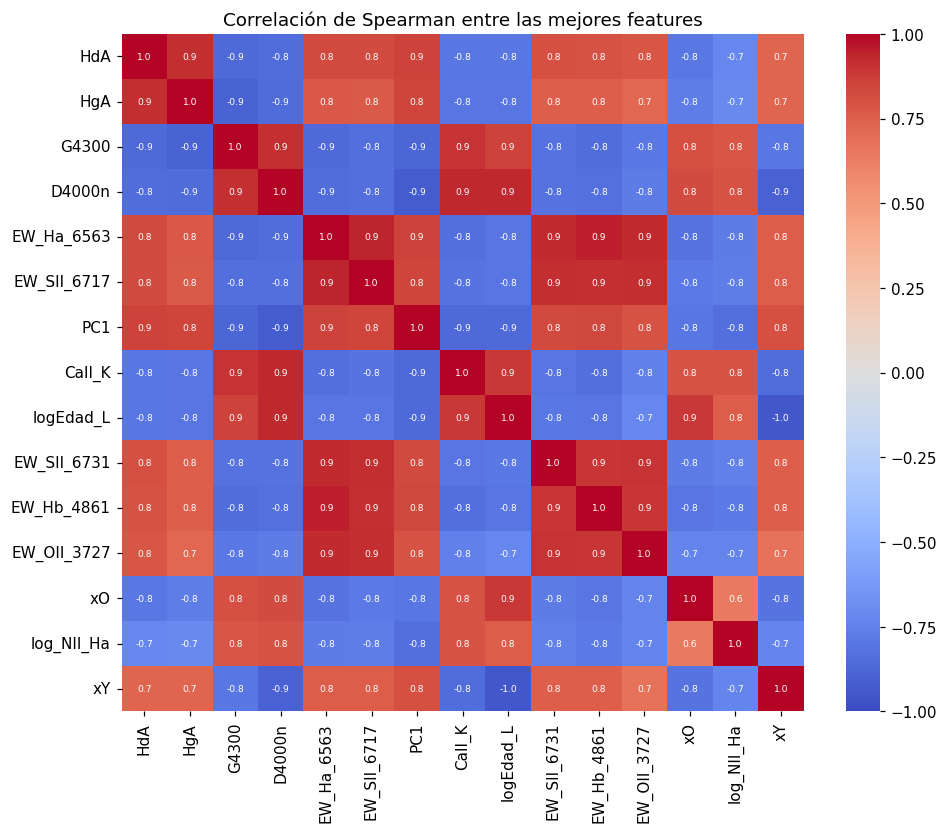

In [ ]:
# Correlación entre las mejores features (muchas miden lo mismo: la edad)
top_f = ranking.head(15).index.tolist()
plt.figure(figsize=(10, 8))
sns.heatmap(d[top_f].corr(method='spearman'), cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 6})
plt.title('Correlación de Spearman entre las mejores features'); plt.show()

# LDA: proyección lineal que maximiza la separación entre grupos (Fisher 1936)
Xs = StandardScaler().fit_transform(X[top_f])
lda = LinearDiscriminantAnalysis(n_components=2).fit(Xs, y)
Z = lda.transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
colores_g = dict(zip(ORDEN_GRUPO, plt.cm.turbo_r(np.linspace(0.02, 0.98, len(ORDEN_GRUPO)))))
for g in ORDEN_GRUPO:
    m = (y == g).values
    if m.any():
        ax[0].scatter(Z[m, 0], Z[m, 1], s=10, color=colores_g[g], label=g)
ax[0].legend(); ax[0].set_xlabel('LD1'); ax[0].set_ylabel('LD2'); ax[0].set_title('LDA con las 15 mejores features')

# Matriz de confusión con validación cruzada (balanced accuracy)
n_cv = int(min(5, y.value_counts().min()))
cv = StratifiedKFold(n_cv, shuffle=True, random_state=0)
print('Balanced accuracy (RF, todas las features):',
      cross_val_score(rf, X, y, cv=cv, scoring='balanced_accuracy').mean().round(3))
y_pred = cross_val_predict(rf, X, y, cv=cv)
ConfusionMatrixDisplay.from_predictions(y, y_pred, labels=[g for g in ORDEN_GRUPO if g in set(y)],
                                        normalize='true', ax=ax[1], cmap='Blues', values_format='.2f')
plt.tight_layout(); plt.show()

# Histogramas (bins de Knuth) de las 4 mejores features por grupo
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, f in zip(ax, top_f[:4]):
    for g in ORDEN_GRUPO:
        v = d.loc[y.index[y == g], f].dropna()
        if len(v) > 5:
            hist_astro(v, bins='knuth', ax=a, histtype='step', density=True, color=colores_g[g], label=g)
    a.set_title(f)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Conclusión del ranking:** según la literatura, las features que mejor separan los tipos deberían ser las
ligadas a la **edad de la población estelar y la formación estelar reciente**: D4000n, EW(Hα), logEdad_L,
PC1, Hδ_A, xO/xY, EW([OII]) y Mg b. Les siguen σ estelar y LogMass (bulbo/masa). La mayoría están muy correlacionadas
entre sí, así que conviene quedarse con 1 o 2 por familia: edad (D4000n o logEdad_L), formación estelar
(EW(Hα)), cinemática (σ) e ionización ([NII]/Hα). La matriz de confusión debería mostrar que E vs. espirales
tardías se distinguen bien, pero los tipos vecinos (S0/Sa, Sb/Sbc/Sc) se confunden.
La espectroscopía integrada mide la **población estelar**, no la **estructura** (brazos, barras): para
afinar la clasificación hay que combinarla con imagen (Domínguez Sánchez et al. 2018, 2022).

conclucion

## Conclusión general
1. Los espectros medios forman una secuencia continua con T-type. El continuo pasa de rojo a azul, el quiebre en
   4000 Å disminuye y crecen las líneas de emisión. Esto confirma el vínculo entre morfología e historia de
   formación estelar.
2. Los diagnósticos BPT y WHAN separan las galaxias tempranas (retiradas, pasivas o LINER) de las tardías (SF).
   Las espirales intermedias ocupan la zona compuesta.
3. Las absorciones de metales (Mg b, G, Ca II K) siguen la secuencia de E a Im en sentido decreciente, y las de
   Balmer (Hδ_A, Hγ_A) en sentido creciente.
4. Las mejores features son D4000n, EW(Hα), la edad pesada por luz, PC1 y Hδ_A, junto con σ y M*.
   Separan bien los grupos amplios, pero no los T-types vecinos. Para eso hace falta añadir información
   estructural (imágenes).

## Referencias
- Baldwin, Phillips & Terlevich 1981, PASP 93, 5 — diagrama BPT
- Balogh et al. 1999, ApJ 527, 54 — D4000n
- Belfiore et al. 2019, AJ 158, 160; Westfall et al. 2019, AJ 158, 231 — DAP de MaNGA
- Blanton & Moustakas 2009, ARA&A 47, 159 — propiedades de galaxias vs. morfología
- Bruzual & Charlot 2003, MNRAS 344, 1000 — modelos SSP BC03
- Bundy et al. 2015, ApJ 798, 7 — MaNGA
- Calzetti, Kinney & Storchi-Bergmann 1994, ApJ 429, 582 — extinción gas vs. estrellas
- Cardelli, Clayton & Mathis 1989, ApJ 345, 245 — ley de extinción CCM
- Cid Fernandes et al. 2005, MNRAS 358, 363 — STARLIGHT
- Cid Fernandes et al. 2011, MNRAS 413, 1687 — diagrama WHAN
- Ciddor 1996, Appl. Opt. 35, 1566 — conversión aire–vacío
- Concas et al. 2019, A&A 622, A188 — NaD interestelar
- Connolly et al. 1995, AJ 110, 1071; Yip et al. 2004, AJ 128, 585 — PCA espectral
- Conselice 2014, ARA&A 52, 291 — estructura y morfología de galaxias
- de Vaucouleurs 1959, Handbuch der Physik 53, 275; de Vaucouleurs et al. 1991 (RC3) — T-type
- Díaz, Terlevich & Terlevich 1989, MNRAS 239, 325 — triplete del Ca II
- Domínguez Sánchez et al. 2018, MNRAS 476, 3661; 2022, MNRAS 509, 4024 — morfología con deep learning (SDSS/MaNGA)
- Dressler & Gunn 1983, ApJ 270, 7 — galaxias post-starburst
- Heckman 1980, A&A 87, 152 — LINERs
- Hubble 1926, ApJ 64, 321; Hubble 1936, *The Realm of the Nebulae*
- Ivezić, Connolly, VanderPlas & Gray 2014/2019, *Statistics, Data Mining, and Machine Learning in Astronomy* — astroML
- Kauffmann et al. 2003a, MNRAS 341, 33 — D4000 y Hδ_A
- Kauffmann et al. 2003b, MNRAS 346, 1055 — línea de demarcación SF en el BPT
- Kennicutt 1992, ApJS 79, 255 — atlas de espectros integrados por tipo
- Kennicutt 1998, ARA&A 36, 189 — trazadores de formación estelar
- Kewley et al. 2001, ApJ 556, 121; Kewley et al. 2006, MNRAS 372, 961 — clasificación BPT
- Osterbrock & Ferland 2006, *Astrophysics of Gaseous Nebulae and AGN* — caso B y densidades
- Pérez et al. 2013, ApJ 764, L1 — downsizing espacialmente resuelto
- Pettini & Pagel 2004, MNRAS 348, L59 — metalicidad N2
- Roberts & Haynes 1994, ARA&A 32, 115 — propiedades físicas a lo largo de la secuencia de Hubble
- Schawinski et al. 2007, MNRAS 382, 1415 — separación Seyfert/LINER
- Stasińska et al. 2008, MNRAS 391, L29 — galaxias retiradas
- Strateva et al. 2001, AJ 122, 1861 — bimodalidad de color
- Trager et al. 1998, ApJS 116, 1; Worthey 1994, ApJS 95, 107; Worthey & Ottaviani 1997, ApJS 111, 377 — índices de Lick
- Tremonti et al. 2004, ApJ 613, 898 — relación masa–metalicidad
- Vázquez-Mata et al. 2022, MNRAS 512, 2222 — morfología visual de MaNGA
- Veilleux & Osterbrock 1987, ApJS 63, 295 — diagramas de diagnóstico